# Proyecto aplicado — Fase 2
## Preprocesamiento y análisis exploratorio de datos (CTI / Threat Intelligence)

| Campo | Valor |
|-------|-------|
| **Autor** | **David Martínez** |
| **Programa** | Diplomado en Machine Learning — Universidad Nacional de Colombia |
| **Curso / módulo** | Módulo 6, Unidad 3 — *Proyecto Fase II* |
| **Cohorte** | **2026-II** |
| **Metodología** | TDSP — *Adquisición, comprensión, preprocesamiento y EDA* |
| **Entorno** | Google Colab o Jupyter (ejecutar celdas **en orden**) |

Continuidad: **Fase 1** (`Proyecto_Fase1_ThreatIntel_Colab.ipynb`). Este cuaderno entrega **ETL**, **auditoría de calidad**, **EDA con enfoque SOC/CTI** y exportación de artefactos para `docs/data/` y Fase 3 (RAG / modelado).


---
## Alcance del proyecto — Fase II (TDSP)

**Proyecto:** Asistente de apoyo a *threat hunting* basado en LLM y datos de Cyber Threat Intelligence (CTI).

### Objetivo de esta fase

Comprender, limpiar y explorar los datos públicos cargados en Fase 1, documentando **calidad**, **desbalance de clases/señales** y decisiones de preprocesamiento que condicionan la Fase 3 (RAG, clasificación, fine-tuning).

### Incluye (Fase II)

| Entregable | Descripción |
|------------|-------------|
| Preprocesamiento (ETL) | Tipado, deduplicación, normalización, **auditoría de desbalance** y variables derivadas |
| EDA por fuente | CVE/CVSS/KEV, MITRE ATT&CK, instrucciones LLM, incidentes Kaggle |
| Artefactos | Parquets en `data/processed/`, figuras en `docs/data/figures/` |
| Documentación | Soporte a `docs/data/data_definition.md`, `data_dictionary.md`, `data_summary.md` |
| Trazabilidad | Preguntas de negocio SOC ↔ variables y decisiones documentadas |

### No incluye (Fase II)

- Entrenamiento, despliegue o evaluación final de un LLM en producción.
- Ingesta de logs, SIEM ni datos internos del negocio (sin gobierno de datos definido).
- Corrección automática de desbalance (SMOTE, undersampling masivo) — solo se **diagnostica y planifica** en ETL; la mitigación se reserva a Fase 3 según métrica de negocio.
- Automatización CI/CD del pipeline SOC.
- Integración MITRE Enterprise completa ni enriquecimiento externo masivo de campos vacíos (p. ej. `detection`).

*Continuidad obligatoria:* Fase 1 (`Proyecto_Fase1_ThreatIntel_Colab.ipynb`) y Project Charter en `docs/business_understanding/project_charter.md`.

| Estrategia multilingüe (EN→ES) | §1.b — auditoría de idioma + plan Colab T4 (Fase 3) |



---
## 1.b Estrategia multilingüe (inglés en datos → español en el asistente)

> **Alcance Fase II:** se **documenta y audita** el idioma; el entrenamiento/despliegue del LLM es **Fase 3**. El negocio (SOC, CISO, analistas) opera en **español**; los datasets públicos (HF + Kaggle) están mayoritariamente en **inglés**.

### Situación actual de los datos (hallazgo EDA)

| Fuente | Idioma dominante | Campos textuales | Implicación |
|--------|------------------|------------------|-------------|
| `cve_data` | **Inglés** (NVD) | `description`, metadatos CVSS | RAG debe permitir consulta en ES sobre texto EN |
| `mitre_attack` | **Inglés** | `description`, `technique_name` | Glosario ATT&CK; respuestas del asistente en ES |
| `instructions_*` | **Inglés** | `instruction`, `input`, `output` | Fine-tuning cross-lingual o traducción controlada |
| `kaggle_cti_2026` | **Inglés** (etiquetas) | Categóricas EN (`severity_level`, `attack_type`) | UI/reportes en ES; datos tabulares traducibles |

### Objetivo del modelo final (Fase 3)

**Asistente multilingüe operativo en español** que:
- Lee contexto CTI en inglés (CVE, MITRE, métricas).
- Responde en **español** con terminología SOC (CVE, MITRE, KEV, CVSS sin traducir de más).
- Ejecuta en **Google Colab con GPU T4** (7–8 GB VRAM útiles).

### Alternativas evaluadas (Fase II — decisión preliminar)

| Enfoque | Descripción | Pros | Contras | Decisión Fase II |
|---------|-------------|------|---------|-----------------|
| **A. Prompting ES sobre RAG EN** | Índice vectorial en inglés; system prompt fuerza respuesta en español | Rápido en T4; sin re-entrenar corpus | Calidad depende del LLM base | **Recomendado para prototipo** |
| **B. QLoRA / LoRA** (`instructions`) | Fine-tune 4-bit (ej. Llama-3.2-3B, Mistral-7B) con pares EN→ES | Alinea estilo analista en ES | VRAM ajustada; riesgo de olvido si solo ES | **Fase 3 principal** |
| **C. Traducir corpus a ES** | MT (NLLB/Marian) sobre `output` y luego fine-tune | Datos homogéneos en ES | Coste; errores MT en términos técnicos | Complemento opcional |
| **D. Modelo multilingüe base** | XLM-RoBERTa, mBERT, o LLM ya multilingüe | Cross-lingual nativo | Menos control del registro SOC colombiano | Baseline / embeddings |

### Stack recomendado Colab T4 (Fase 3 — referencia)

```text
Carga: 4-bit NF4 (bitsandbytes) + LoRA (peft)
Modelos candidatos: meta-llama/Llama-3.2-3B-Instruct | mistralai/Mistral-7B-Instruct-v0.3
RAG: sentence-transformers paraphrase-multilingual-MiniLM-L12-v2 (opcional)
Evaluación: respuestas en ES (ROUGE-L, BERTScore-es, revisión humana SOC)
```

**Auditoría de idioma (código):** ver **§3.1** (no ejecutar la celda de código que aparecía aquí; fue movida tras la carga).

**Nota Fase II:** este notebook **no entrena** el LLM; deja trazabilidad para la rúbrica (EDA + decisión de diseño).


### Análisis de resultados — §1.b Idioma y estrategia multilingüe

**§ Pertenece a:** visión de producto (Fase 3) y auditoría §3.1.

#### Hechos (datos de esta ejecución)
- La **auditoría cuantitativa de idioma** se ejecuta en **§3.1** (tras cargar datos y definir `sec_out` en §2).
- Objetivo documentado: datos en **inglés**, operación del SOC en **español** (sin traducir corpus en Fase II).

#### Interpretación (ciberseguridad / CTI)
- El asistente debe leer CTI en inglés (NVD, MITRE) y responder en español conservando identificadores (CVE, KEV, TTP).

#### Implicación (ciencia de datos / Fase 3)
- RAG + *system prompt* en español; QLoRA T4 opcional sobre `instructions_*`.

#### Limitaciones
- La estrategia multilingüe aquí es **diseño**; la evaluación en español corresponde a Fase 3.


---
## 1. Trazabilidad — Rúbrica Fase 2 (10 % del proyecto)

| Criterio [4.0 – 5.0] | Sección |
|----------------------|---------|
| Código de preprocesamiento (limpieza, nulos, transformación) | §3 – §5 |
| Código de EDA (estadísticos, visualizaciones, **NLP**) | §6 – §10 |
| Definición de datos (formatos, variables, proyecto) | `docs/data/data_definition.md` |
| Reporte resumen + **conclusiones** | `docs/data/data_summary.md` + análisis en este notebook |

### Preguntas de negocio → análisis

| Pregunta CTI / SOC | Sección |
|--------------------|---------|
| ¿CVE de mayor riesgo y en KEV? | §6 |
| ¿Tácticas MITRE dominantes? | §6 – §7 |
| ¿Patrones de incidente y detección? | §9 |
| ¿Severidad vs impacto y MTTR? | §9 |
| ¿Corpus LLM utilizable (NLP/TF-IDF/embeddings)? | §8 |
| ¿Correlación entre fuentes CTI? | §10 |
| ¿Idioma datos EN vs respuesta ES? | §1.b, §3.1 |


---
## 2. Preparación del entorno

Instale dependencias. Si aparece `TqdmWarning: IProgress not found`, es opcional (`pip install ipywidgets`). Reinicie el kernel si Colab lo solicita.


In [1]:
# --- Celda: §2 — Instalación de dependencias (ejecutar primero en Colab) ---
print("\n" + "=" * 72)
print("  SALIDA — §2 — Preparación del entorno (instalación de dependencias)")
print("=" * 72)
%pip install -q "pandas>=2.0" "datasets>=2.14" "kagglehub[pandas-datasets]" "matplotlib>=3.7" "seaborn>=0.13" "pyarrow>=14" "scikit-learn>=1.3" "nltk>=3.8" "gensim>=4.3" "scipy>=1.11" "langdetect>=1.0.9"



  SALIDA — §2 — Preparación del entorno (instalación de dependencias)


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Análisis de resultados — §2.1 Instalación de dependencias

**§ Pertenece a:** §2 Preparación del entorno — `%pip install`.

#### Hechos (datos de esta ejecución)
- Instalación completada; mensaje: *Note: you may need to restart the kernel to use updated packages.*
- Aviso de pip: hay release más nueva disponible (no bloqueante).
- Pin crítico: **`langdetect>=1.0.9`** (no existe 1.2 en PyPI).

#### Interpretación
- Entorno listo para HF (`datasets`), Kaggle (`kagglehub`), NLP (`nltk`, `gensim`) y EDA tabular.

#### Implicación
- En Colab/local nuevo: ejecutar esta celda **antes** de imports; reiniciar kernel solo si pip lo exige.

#### Limitaciones
- `%pip` puede reinstalar en cada corrida (tiempo); en entorno ya provisionado es redundante pero reproducible.


In [2]:
# --- Celda: §2 — Imports, rutas del proyecto y configuración global ---
import warnings
import re
import string
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "figure.titlesize": 14})

# --- NLTK (tokenización, lematización, stopwords) ---
import nltk
for _pkg in ("punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"):
    try:
        nltk.download(_pkg, quiet=True)
    except Exception:
        pass
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# --- Gensim (Word2Vec, FastText, Doc2Vec) ---
try:
    from gensim.models import Word2Vec, FastText, Doc2Vec
    from gensim.models.doc2vec import TaggedDocument
    GENSIM_OK = True
except ImportError:
    GENSIM_OK = False
    print("gensim no disponible — omitir celdas W2V/FastText/Doc2Vec")


def sec_out(seccion: str) -> None:
    """Imprime cabecera visible en la salida de la celda (trazabilidad por sección)."""
    bar = "=" * 72
    print(f"\n{bar}\n  SALIDA — {seccion}\n{bar}")


sec_out("§2 — Preparación del entorno")

def find_project_root(start: Path) -> Path:
    """Sube directorios y elige el ancestro más alto que contenga docs/data/."""
    current = start.resolve()
    candidates = []
    for _ in range(12):
        if (current / "docs" / "data").is_dir():
            candidates.append(current)
        if current.parent == current:
            break
        current = current.parent
    return candidates[-1] if candidates else start.resolve()

PROJECT_ROOT = find_project_root(Path.cwd())
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "docs" / "data" / "figures"
for p in (DATA_PROCESSED, FIGURES_DIR):
    p.mkdir(parents=True, exist_ok=True)

HF_ID = "Shomi28/cyber-threat-intelligence"
HF_BASE = f"hf://datasets/{HF_ID}"
KAGGLE_HANDLE = "prayanshusinghgaur/cybersecurity-threat-intelligence"
PARQUET_MAP = {
    "cve_data": f"{HF_BASE}/cve_data/train-00000-of-00001.parquet",
    "mitre_attack": f"{HF_BASE}/mitre_attack/train-00000-of-00001.parquet",
    "instructions_train": f"{HF_BASE}/instructions/train-00000-of-00001.parquet",
    "instructions_test": f"{HF_BASE}/instructions/test-00000-of-00001.parquet",
}
BOOL_MAP = {"true": True, "false": False, "yes": True, "no": False, "1": True, "0": False}
SEV_ORDER = ["Critical", "High", "Medium", "Low"]

# Stopwords CTI: conservar negaciones y términos de seguridad frecuentes
_BASE_STOPS = set(stopwords.words("english"))
CYBER_KEEP = {"no", "not", "nor", "cve", "attack", "risk", "critical", "high", "low"}
CYBER_STOPS = _BASE_STOPS - CYBER_KEEP
lemmatizer = WordNetLemmatizer()

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Figuras ->", FIGURES_DIR)
print("Gensim OK:", GENSIM_OK)



C:\Users\J2KUSER\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



  SALIDA — §2 — Preparación del entorno
PROJECT_ROOT: C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 6\Unidad 3\Proyecto II
Figuras -> C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 6\Unidad 3\Proyecto II\docs\data\figures
Gensim OK: True


### Análisis de resultados — §2.2 Imports y configuración global

**§ Pertenece a:** §2 Preparación del entorno — imports, rutas TDSP y semillas.

#### Hechos (datos de esta ejecución)
- `PROJECT_ROOT`: `C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 6\Unidad 3\Proyecto II`
- `Figuras ->`: `...\Proyecto II\docs\data\figures`
- `DATA_PROCESSED`: `...\Proyecto II\data\processed`
- **Gensim OK: True** (Word2Vec / Doc2Vec disponibles)

#### Interpretación (ciencia de datos / CTI)
- `find_project_root()` eligió la raíz TDSP (ancestro más externo con `docs/data/`), no el árbol interno de `scripts/`.
- Advertencia `TqdmWarning: IProgress` es cosmética (falta `ipywidgets`); no afecta ETL/EDA.

#### Implicación Fase 3
- Todos los artefactos (parquets/PNG) deben escribirse bajo estas rutas canónicas para el pipeline RAG/modelado.

#### Limitaciones
- Si se abre el notebook con CWD fuera del repo y sin `docs/data` en ancestros, `PROJECT_ROOT` puede resolverse mal — ejecutar desde la raíz del proyecto.


In [3]:
sec_out("§2 — Utilidades NLP (limpieza y vectorización)")

# --- Celda: §2 — Utilidades NLP (limpieza y vectorización) ---
# =============================================================================
# Utilidades NLP — CTI / Threat Hunting (clásico + contextual)
# =============================================================================
URL_RE = re.compile(r"https?://\S+|www\.\S+")
CVE_RE = re.compile(r"CVE-\d{4}-\d{4,7}", re.I)
NON_ALPHA_RE = re.compile(r"[^a-z0-9\s\-_/]")
MULTISPACE_RE = re.compile(r"\s+")


def clean_text_cti(text, lowercase=True, strip_urls=True, normalize_digits=False):
    """Limpieza: URLs, regex, normalización de espacios."""
    if pd.isna(text):
        return ""
    t = str(text)
    if strip_urls:
        t = URL_RE.sub(" ", t)
    if normalize_digits:
        t = re.sub(r"\d+", " NUM ", t)
    t = NON_ALPHA_RE.sub(" ", t.lower() if lowercase else t)
    t = MULTISPACE_RE.sub(" ", t).strip()
    return t


def tokenize_text(text):
    return word_tokenize(clean_text_cti(text))


def lemmatize_tokens(tokens):
    return [lemmatizer.lemmatize(t) for t in tokens if t.isalnum() and len(t) > 1 and t not in CYBER_STOPS]


def spelling_variants(text):
    """Proxy de variación ortográfica: ratio caracteres únicos / longitud."""
    t = clean_text_cti(text)
    if not t:
        return 0.0
    return len(set(t)) / len(t)


def bow_ngram_tfidf(corpus, ngram_range=(1, 1), max_features=800, name="tfidf"):
    vec = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, stop_words=list(CYBER_STOPS))
    X = vec.fit_transform(corpus)
    return X, vec


def top_tfidf_terms(vec, X, top_k=15):
    scores = np.asarray(X.mean(axis=0)).ravel()
    idx = scores.argsort()[::-1][:top_k]
    names = vec.get_feature_names_out()
    return pd.Series(scores[idx], index=names[idx])


def train_w2v(sentences, vector_size=100, epochs=8, model_type="w2v"):
    if not GENSIM_OK:
        return None
    sents = [[w for w in sent if w] for sent in sentences]
    if model_type == "fasttext":
        return FastText(sentences=sents, vector_size=vector_size, window=5, min_count=2, workers=2, epochs=epochs)
    return Word2Vec(sentences=sents, vector_size=vector_size, window=5, min_count=2, workers=2, epochs=epochs)


def train_doc2vec(tagged_docs, vector_size=100, epochs=10):
    if not GENSIM_OK:
        return None
    return Doc2Vec(tagged_docs, vector_size=vector_size, window=5, min_count=2, workers=2, epochs=epochs, dm=1)


def doc_vectors_from_tokens(token_lists, vector_size=100):
    if not GENSIM_OK:
        return None
    tagged = [TaggedDocument(words=toks, tags=[i]) for i, toks in enumerate(token_lists) if toks]
    model = Doc2Vec(vector_size=vector_size, window=5, min_count=2, workers=2, epochs=8, dm=1)
    model.build_vocab(tagged)
    model.train(tagged, total_examples=model.corpus_count, epochs=model.epochs)
    return np.array([model.dv[i] for i in range(len(tagged))]), model

print("Utilidades NLP cargadas.")



  SALIDA — §2 — Utilidades NLP (limpieza y vectorización)
Utilidades NLP cargadas.


### Análisis de resultados — §2.3 Utilidades NLP

**§ Pertenece a:** §2 Preparación del entorno.

#### Hechos (datos de esta ejecución)
- Salida: `Utilidades NLP cargadas.`

#### Interpretación (ciberseguridad / CTI)
- Funciones de limpieza CTI, TF-IDF, BoW y embeddings listas para §6–§8.

#### Implicación (ciencia de datos / Fase 3)
- Reutilizar `clean_text_cti`, `tokenize_text`, `lemmatize_tokens` en pipeline de inferencia.

#### Limitaciones
- La carga de utilidades no valida calidad del corpus (solo disponibilidad de código).


---
## 3. Carga de datos

Misma estrategia que Fase 1: Parquet por bloque en HF (evita fallo del builder monolítico) y CSV Kaggle vía `kagglehub`.


In [4]:
sec_out("§3 — Carga de datos (HF + Kaggle)")

# --- Celda: §3 — Carga de datos (HF + Kaggle) ---
def load_hf_block(name: str) -> pd.DataFrame:
    """Carga un bloque Parquet del dataset Hugging Face."""
    ds = load_dataset("parquet", data_files=PARQUET_MAP[name])
    return ds["train"].to_pandas()


def load_kaggle() -> pd.DataFrame:
    """Descarga y lee el CSV de incidentes CTI desde Kaggle Hub."""
    import kagglehub
    root = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
    csv_path = sorted(root.rglob("*.csv"))[0]
    print("Kaggle CSV:", csv_path.name)
    return pd.read_csv(csv_path)


print("Cargando bloques Hugging Face…")
df_cve_raw = load_hf_block("cve_data")
df_mitre_raw = load_hf_block("mitre_attack")
df_inst_train_raw = load_hf_block("instructions_train")
df_inst_test_raw = load_hf_block("instructions_test")
df_kaggle_raw = load_kaggle()

datasets_summary = pd.DataFrame([
    {"tabla": "cve_data", "filas": len(df_cve_raw), "columnas": df_cve_raw.shape[1]},
    {"tabla": "mitre_attack", "filas": len(df_mitre_raw), "columnas": df_mitre_raw.shape[1]},
    {"tabla": "instructions_train", "filas": len(df_inst_train_raw), "columnas": 3},
    {"tabla": "instructions_test", "filas": len(df_inst_test_raw), "columnas": 3},
    {"tabla": "kaggle_cti_2026", "filas": len(df_kaggle_raw), "columnas": df_kaggle_raw.shape[1]},
])
display(datasets_summary)



  SALIDA — §3 — Carga de datos (HF + Kaggle)
Cargando bloques Hugging Face…


C:\Users\J2KUSER\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\J2KUSER\.cache\huggingface\hub\datasets--Shomi28--cyber-threat-intelligence. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 5000 examples [00:00, 61270.07 examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 697 examples [00:00, 73386.63 examples/s]

... (6 outputs left out)

100%|██████████| 1.26M/1.26M [00:00<00:00, 2.94MB/s]

Extracting files...


Kaggle CSV: Cybersecurity_Threat_Intelligence_2026.csv


,tabla,filas,columnas
0,cve_data,5000,28
1,mitre_attack,697,11
2,instructions_train,14189,3
3,instructions_test,1577,3
4,kaggle_cti_2026,50000,15


### Análisis de resultados — §3 Carga de datos (HF + Kaggle)

**§ Pertenece a:** §3 — carga cruda previa a ETL.

#### Hechos (datos de esta ejecución)

| tabla | filas | columnas |
|-------|------:|---------:|
| `cve_data` | **5000** | 28 |
| `mitre_attack` | **697** | 11 |
| `instructions_train` | **14189** | 3 |
| `instructions_test` | **1577** | 3 |
| `kaggle_cti_2026` | **50000** | 15 |

- HF: bloques Parquet cargados (splits train generados en memoria).
- Kaggle: `Cybersecurity_Threat_Intelligence_2026.csv` vía `kagglehub`.
- Warning HF: requests **no autenticados** (rate limit); cache Windows sin symlinks (espacio extra posible).

#### Interpretación (CTI)
- Cinco tablas lógicas alineadas al diseño del asistente: CVE/KEV + MITRE + corpus LLM + incidentes SOC sintéticos.

#### Implicación Fase 3 / ETL
- Pasar a §4 para tipado, nulos literales (`"nan"`) y claves; no modelar sobre crudos tipados como string en HF.

#### Limitaciones
- Sin `HF_TOKEN` la descarga es más lenta/frágil; Kaggle requiere caché o credenciales previas.


### 3.1 Auditoría de idioma

> Ejecutar **solo después** de la celda de carga (§3). Requiere `sec_out` definido en §2.


In [5]:
sec_out("§3.1 — Auditoría de idioma (post-carga)")

# --- Celda: §3.1 — Auditoría de idioma ---
# Ejecutar después de §2 (imports) y de la carga HF/Kaggle (celda anterior).
try:
    from langdetect import detect, LangDetectException
    HAS_LANGDETECT = True
except ImportError:
    HAS_LANGDETECT = False
    print("Instalar langdetect: pip install langdetect")

EN_MARKERS = {"the", "and", "vulnerability", "attack", "risk", "critical", "patch", "cve"}
ES_MARKERS = {"el", "la", "vulnerabilidad", "ataque", "riesgo", "crítico", "parche", "amenaza"}


def guess_lang(text: str) -> str:
    """Detecta idioma (langdetect o marcadores EN/ES)."""
    t = str(text)[:2000].lower()
    if not t.strip():
        return "empty"
    if HAS_LANGDETECT:
        try:
            return detect(t)
        except LangDetectException:
            pass
    en = sum(1 for w in EN_MARKERS if f" {w} " in f" {t} ")
    es = sum(1 for w in ES_MARKERS if f" {w} " in f" {t} ")
    if en > es:
        return "en (heuristic)"
    if es > en:
        return "es (heuristic)"
    return "unknown"


def audit_lang(series, name, n=500):
    """Muestra distribución de idioma en una columna textual."""
    sample = series.dropna().astype(str).sample(min(n, len(series)), random_state=42)
    langs = sample.map(guess_lang).value_counts(normalize=True).mul(100).round(1)
    print(f"--- {name} (n={len(sample)}) ---")
    display(langs.to_frame("%"))


audit_lang(df_cve_raw["description"], "cve_data.description", 800)
audit_lang(df_mitre_raw["description"], "mitre_attack.description", 400)
audit_lang(df_inst_train_raw["instruction"], "instructions.instruction", 1000)
audit_lang(df_inst_train_raw["output"], "instructions.output", 1000)
print("\nConclusión: predominio EN → asistente en ES (prompt/QLoRA, Fase 3).")



  SALIDA — §3.1 — Auditoría de idioma (post-carga)


--- cve_data.description (n=800) ---


,%
description,
en,99.9
da,0.1


--- mitre_attack.description (n=400) ---


,%
description,
en,100.0


--- instructions.instruction (n=1000) ---


,%
instruction,
en,100.0


--- instructions.output (n=1000) ---


,%
output,
en,100.0



Conclusión: predominio EN → asistente en ES (prompt/QLoRA, Fase 3).


### Análisis de resultados — §3.1 Auditoría de idioma

**§ Pertenece a:** §3.1 — auditoría post-carga (gate 24/11/2026).

#### Hechos (datos)
- **Método:** `langdetect==1.0.9` activo (corrida end-to-end sin fallback heurístico).
- `cve_data.description` (n=800): **en 99,9 %**, da 0,1 %.
- `mitre_attack.description` (n=400): **en 100 %**.
- `instructions.instruction` / `output` (n=1000 c/u): **en 100 %**.

#### Interpretación CTI
- Corpus técnico y de instrucciones está en **inglés**; coherente con fuentes NVD/MITRE/CISA y datasets HF.

#### Implicación Fase 3
- Asistente debe **responder en español** vía system prompt / QLoRA / post-procesado, sin traducir masivamente el índice RAG en Fase 2.

#### Limitaciones
- Muestras parciales (800/400/1000); `langdetect` puede etiquetar ruido puntual (p. ej. 0,1 % `da` en CVE).


---
## 4. Preprocesamiento (ETL) y tratamiento del desbalance

En este proyecto coexisten **cinco tablas** con perfiles de desbalance **distintos**. Esta sección hace tres cosas:

1. **ETL:** limpieza, tipado y variables derivadas (sin cambiar el tamaño de las clases).
2. **Diagnóstico:** cuantificar el desbalance por variable relevante en cada fuente.
3. **Decisiones Fase II:** documentar **qué se hace y qué no se hace** con datos desbalanceados antes del modelado (Fase 3).

> **Regla de Fase II:** no aplicar SMOTE, undersampling masivo ni generación sintética de clases. El desbalance se **preserva y se documenta** para elegir métricas y mitigaciones correctas en Fase 3.


### 4.0 Los cinco conjuntos y su tipo de desbalance

| # | Conjunto | Filas | ¿Desbalanceado? | Naturaleza del desbalance |
|---|----------|------:|:---------------:|---------------------------|
| 1 | `cve_data` | 5 000 | **Sí — severo** | ~99 % `CRITICAL`; KEV ~1.8 %; `Unknown` en táctica MITRE ~40 % |
| 2 | `mitre_attack` | 697 | **Sí — moderado** | Táctica `Stealth` y otras concentran el conteo; ~68 % sub-técnicas |
| 3 | `instructions_train` | 14 189 | **Sí — funcional** | Tipos de tarea (`task_type`) no uniformes; ratio volumen vs test ~9:1 |
| 4 | `instructions_test` | 1 577 | **Sí — diseño** | Hold-out del Hub (no se rebalancea respecto a train) |
| 5 | `kaggle_cti_2026` | 50 000 | **No (casi balanceado)** | `severity_level` y `attack_type` ~equiproporcionados (~25 % / ~17 % c/u) — **excepción** frente a HF |

**Por qué importa en ciberseguridad:** en operación real (SOC) las clases críticas suelen ser **minoritarias** (KEV, ransomware activo, técnicas avanzadas). Un modelo o asistente entrenado asumiendo balance artificial puede **subestimar el riesgo real**.


### 4.1 Transformaciones ETL (código siguiente)

- Deduplicación por `cve_id`, `technique_id`, `incident_id`.
- Tipado: fechas, CVSS numérico, booleanos `in_cisa_kev` / `exploit_available`.
- Derivadas: `desc_len`, `published_year`, `tactic_primary`, `incident_date`, `loss_musd`.
- **Sin remuestreo:** el número de filas por clase permanece igual que en el origen.


In [6]:
sec_out("§4.1 — Transformaciones ETL (código siguiente)")

# --- Celda: §4.1 — Transformaciones ETL (código siguiente) ---
def parse_bool(series: pd.Series) -> pd.Series:
    return series.astype(str).str.strip().str.lower().map(BOOL_MAP)


def preprocess_cve(df: pd.DataFrame) -> pd.DataFrame:
    out = df.drop_duplicates(subset=["cve_id"]).copy()
    for col in ("published_date", "last_modified"):
        out[col] = pd.to_datetime(out[col], errors="coerce")
    for col in ("cvss_score", "exploitability_score", "impact_score", "risk_score"):
        out[col] = pd.to_numeric(out[col], errors="coerce")
    for col in ("exploit_available", "in_cisa_kev"):
        out[col] = parse_bool(out[col])
    out["cvss_severity"] = out["cvss_severity"].astype(str).str.strip().str.upper()
    out["risk_level"] = out["risk_level"].astype(str).str.strip().str.upper()
    for col in ("description", "cwe_ids", "likely_mitre_tactic"):
        out[col] = out[col].astype(str).str.strip()
        out.loc[out[col].isin(["", "nan", "None"]), col] = pd.NA
    out["desc_len"] = out["description"].str.len()
    out["published_year"] = out["published_date"].dt.year
    return out


def preprocess_mitre(df: pd.DataFrame) -> pd.DataFrame:
    out = df.drop_duplicates(subset=["technique_id"]).copy()
    out["is_subtechnique"] = parse_bool(out["is_subtechnique"])
    for col in ("created", "modified"):
        out[col] = pd.to_datetime(out[col], errors="coerce")
    out["detection"] = out["detection"].replace("nan", pd.NA)
    out["tactic_primary"] = out["tactics"].astype(str).str.split("|").str[0].str.strip()
    out["desc_len"] = out["description"].astype(str).str.len()
    out["n_tactics_listed"] = out["tactics"].astype(str).str.count("|") + 1
    return out


def preprocess_kaggle(df: pd.DataFrame) -> pd.DataFrame:
    out = df.drop_duplicates(subset=["incident_id"]).copy()
    out["severity_level"] = out["severity_level"].astype(str).str.strip().str.title()
    out["incident_month"] = out["incident_month"].clip(1, 12)
    out["incident_date"] = pd.to_datetime(dict(year=out["incident_year"], month=out["incident_month"], day=1))
    for col in ["country", "industry", "attack_type", "attack_vector", "detection_method", "response_action_taken"]:
        out[col] = out[col].astype(str).str.strip()
    out["loss_musd"] = out["estimated_financial_loss_usd"] / 1e6
    return out


df_cve = preprocess_cve(df_cve_raw)
df_mitre = preprocess_mitre(df_mitre_raw)
df_kaggle = preprocess_kaggle(df_kaggle_raw)
print("ETL completado (sin remuestreo):", df_cve.shape, df_mitre.shape, df_kaggle.shape)



  SALIDA — §4.1 — Transformaciones ETL (código siguiente)


ETL completado (sin remuestreo): (5000, 30) (697, 14) (50000, 17)


### Análisis de resultados — §4.1 Transformaciones ETL

**§ Pertenece a:** §4.1 ETL.

#### Hechos (datos de esta ejecución)
- `ETL completado (sin remuestreo): (5000, 30) (697, 14) (50000, 17)`

#### Interpretación (ciberseguridad / CTI)
- Tipado, fechas y variables derivadas aplicados sin alterar cardinalidad de filas.

#### Implicación (ciencia de datos / Fase 3)
- Parquets limpios en `data/processed/` para modelado.

#### Limitaciones
- ETL no corrige desbalance (decisión documentada en §4.2).


### 4.2 Diagnóstico cuantitativo del desbalance (código siguiente)

Las tablas impresas muestran, por cada variable: **conteo**, **porcentaje %** y **ratio_max_min** (clase mayoritaria / minoritaria). Valores altos de ratio indican desbalance fuerte.


In [7]:
sec_out("§4.2 — Diagnóstico de desbalance")

# --- Celda: §4.2 — Diagnóstico de desbalance ---
def imbalance_table(series: pd.Series, name: str) -> pd.DataFrame:
    """Tabla de conteos y porcentajes por clase."""
    vc = series.value_counts(dropna=False)
    pct = (vc / vc.sum() * 100).round(2)
    ratio = round(vc.max() / max(vc.min(), 1), 2) if len(vc) > 1 else np.nan
    return pd.DataFrame({
        "dataset_var": name,
        "clase": vc.index.astype(str),
        "conteo": vc.values,
        "porcentaje_%": pct.values,
        "ratio_max_min": ratio,
    })


def report_imbalance(df: pd.DataFrame, columns: list, title: str) -> pd.DataFrame:
    """Reporta desbalance para varias columnas categóricas."""
    parts = [imbalance_table(df[col], f"{title}.{col}") for col in columns if col in df.columns]
    rep = pd.concat(parts, ignore_index=True)
    print(f"\n{'='*60}\nDESBALANCE — {title}\n{'='*60}")
    display(rep)
    return rep


# --- 1) CVE (Hugging Face) — desbalance SEVERO en severidad; minoría KEV ---
imb_cve = report_imbalance(
    df_cve,
    ["cvss_severity", "risk_level", "in_cisa_kev", "exploit_available", "likely_mitre_tactic"],
    "cve_data",
)

# --- 2) MITRE — desbalance en táctica y tipo sub-técnica ---
imb_mitre = report_imbalance(
    df_mitre,
    ["tactic_primary", "is_subtechnique"],
    "mitre_attack",
)

# --- 3) Kaggle — referencia casi BALANCEADA (contraste metodológico) ---
imb_kaggle = report_imbalance(
    df_kaggle,
    ["severity_level", "attack_type", "detection_method"],
    "kaggle_cti_2026",
)

# --- 4) Instrucciones — desbalance de tarea y de volumen train/test ---
TASK_PATTERNS = {
    "risk_assessment": r"risk|severity|score|calculate",
    "remediation": r"remediat|patch|fix|mitigat",
    "explanation": r"explain|describe|what is|overview",
    "detection": r"detect|indicator|hunt|log",
    "comparison": r"compare|difference|versus",
}


def infer_task(text: str) -> str:
    """Clasifica heurísticamente el tipo de tarea LLM desde instruction."""
    t = str(text).lower()
    for task, pat in TASK_PATTERNS.items():
        if pd.Series([t]).str.contains(pat, regex=True).iloc[0]:
            return task
    return "other"


imb_inst_parts = []
for label, dfi in [("train", df_inst_train_raw), ("test", df_inst_test_raw)]:
    tmp = dfi.copy()
    tmp["task_type"] = tmp["instruction"].map(infer_task)
    print(f"\n--- instructions_{label} — task_type ---")
    display(imbalance_table(tmp["task_type"], f"instructions_{label}.task_type"))
    imb_inst_parts.append(tmp)

ratio_split = len(df_inst_train_raw) / len(df_inst_test_raw)
print(f"\nRatio volumen train/test: {ratio_split:.2f}:1  ({len(df_inst_train_raw):,} / {len(df_inst_test_raw):,})")



  SALIDA — §4.2 — Diagnóstico de desbalance

DESBALANCE — cve_data


,dataset_var,clase,conteo,porcentaje_%,ratio_max_min
0,cve_data.cvss_severity,CRITICAL,4944,98.88,1236.00
1,cve_data.cvss_severity,HIGH,26,0.52,1236.00
2,cve_data.cvss_severity,MEDIUM,26,0.52,1236.00
3,cve_data.cvss_severity,LOW,4,0.08,1236.00
4,cve_data.risk_level,CRITICAL,4051,81.02,2025.50
5,cve_data.risk_level,HIGH,923,18.46,2025.50
6,cve_data.risk_level,MEDIUM,24,0.48,2025.50
7,cve_data.risk_level,LOW,2,0.04,2025.50
8,cve_data.in_cisa_kev,False,4908,98.16,53.35
9,cve_data.in_cisa_kev,True,92,1.84,53.35



DESBALANCE — mitre_attack


,dataset_var,clase,conteo,porcentaje_%,ratio_max_min
0,mitre_attack.tactic_primary,Stealth,148,21.23,9.87
1,mitre_attack.tactic_primary,Persistence,64,9.18,9.87
2,mitre_attack.tactic_primary,Defense Impairment,56,8.03,9.87
3,mitre_attack.tactic_primary,Credential Access,52,7.46,9.87
4,mitre_attack.tactic_primary,Resource Development,50,7.17,9.87
5,mitre_attack.tactic_primary,Reconnaissance,46,6.60,9.87
6,mitre_attack.tactic_primary,Execution,46,6.60,9.87
7,mitre_attack.tactic_primary,Discovery,43,6.17,9.87
8,mitre_attack.tactic_primary,Command and Control,41,5.88,9.87
9,mitre_attack.tactic_primary,Collection,36,5.16,9.87



DESBALANCE — kaggle_cti_2026


,dataset_var,clase,conteo,porcentaje_%,ratio_max_min
0,kaggle_cti_2026.severity_level,High,12522,25.04,1.00
1,kaggle_cti_2026.severity_level,Low,12511,25.02,1.00
2,kaggle_cti_2026.severity_level,Medium,12492,24.98,1.00
3,kaggle_cti_2026.severity_level,Critical,12475,24.95,1.00
4,kaggle_cti_2026.attack_type,Zero-Day Exploit,8425,16.85,1.03
5,kaggle_cti_2026.attack_type,Malware,8381,16.76,1.03
6,kaggle_cti_2026.attack_type,Ransomware,8337,16.67,1.03
7,kaggle_cti_2026.attack_type,Phishing,8324,16.65,1.03
8,kaggle_cti_2026.attack_type,DDoS,8318,16.64,1.03
9,kaggle_cti_2026.attack_type,SQL Injection,8215,16.43,1.03



--- instructions_train — task_type ---


,dataset_var,clase,conteo,porcentaje_%,ratio_max_min
0,instructions_train.task_type,other,5146,36.27,35.74
1,instructions_train.task_type,remediation,4569,32.20,35.74
2,instructions_train.task_type,risk_assessment,2710,19.10,35.74
3,instructions_train.task_type,explanation,1620,11.42,35.74
4,instructions_train.task_type,detection,144,1.01,35.74



--- instructions_test — task_type ---


,dataset_var,clase,conteo,porcentaje_%,ratio_max_min
0,instructions_test.task_type,other,565,35.83,40.36
1,instructions_test.task_type,remediation,529,33.54,40.36
2,instructions_test.task_type,risk_assessment,303,19.21,40.36
3,instructions_test.task_type,explanation,166,10.53,40.36
4,instructions_test.task_type,detection,14,0.89,40.36



Ratio volumen train/test: 9.00:1  (14,189 / 1,577)


### Análisis de resultados — §4.2 Diagnóstico de desbalance

**§ Pertenece a:** §4.2 — tablas `imbalance_table` / `report_imbalance` (salida inmediata arriba).

#### Hechos (datos de esta ejecución)

**A) `cve_data` (N = 5 000)**

| Variable | Clase dominante / crítica | Conteo | % | ratio max/min |
|----------|---------------------------|-------:|--:|--------------:|
| `cvss_severity` | CRITICAL | 4 944 | 98.88 | **1 236.00** |
| `cvss_severity` | HIGH / MEDIUM / LOW | 26 / 26 / 4 | 0.52 / 0.52 / 0.08 | — |
| `risk_level` | CRITICAL | 4 051 | 81.02 | **2 025.50** |
| `risk_level` | HIGH | 923 | 18.46 | — |
| `risk_level` | MEDIUM / LOW | 24 / 2 | 0.48 / 0.04 | — |
| `in_cisa_kev` | False vs **True** | 4 908 vs **92** | 98.16 vs **1.84** | **53.35** |
| `exploit_available` | True vs False | 4 081 vs 919 | 81.62 vs 18.38 | 4.44 |
| `likely_mitre_tactic` | Unknown | 1 977 | 39.54 | **94.14** |
| `likely_mitre_tactic` | Execution | 1 686 | 33.72 | — |
| `likely_mitre_tactic` | Initial Access | 1 005 | 20.10 | — |
| `likely_mitre_tactic` | Credential Access / Collection / Defense Evasion / Privilege Escalation | 130 / 99 / 82 / **21** | 2.60 / 1.98 / 1.64 / **0.42** | — |

**B) `mitre_attack` (N = 697)**

| Variable | Hallazgo | Conteo | % | ratio |
|----------|----------|-------:|--:|-----:|
| `tactic_primary` | Stealth (máx.) | 148 | 21.23 | **9.87** |
| `tactic_primary` | Persistence | 64 | 9.18 | — |
| `tactic_primary` | Defense Impairment … Initial Access (cola) | 56 … **15** | 8.03 … **2.15** | — |
| `is_subtechnique` | True (sub) vs False (padre) | 475 vs 222 | 68.15 vs 31.85 | 2.14 |

**C) `kaggle_cti_2026` (N = 50 000) — contraste casi uniforme**

| Variable | Rango de % por clase | ratio max/min |
|----------|----------------------|--------------:|
| `severity_level` | High 25.04 · Low 25.02 · Medium 24.98 · Critical 24.95 | **1.00** |
| `attack_type` | Zero-Day 16.85 … SQL Injection 16.43 | 1.03 |
| `detection_method` | SIEM 16.98 … Manual Review 16.42 | 1.03 |

**D) `instructions_*` — `task_type` heurístico (regex sobre `instruction`)**

| Split | other | remediation | risk_assessment | explanation | detection | ratio |
|-------|------:|------------:|----------------:|------------:|----------:|------:|
| train (14 189) | 5 146 (36.27%) | 4 569 (32.20%) | 2 710 (19.10%) | 1 620 (11.42%) | **144 (1.01%)** | 35.74 |
| test (1 577) | 565 (35.83%) | 529 (33.54%) | 303 (19.21%) | 166 (10.53%) | **14 (0.89%)** | 40.36 |

- Ratio volumen train/test: **9.00:1** (14 189 / 1 577).
- Proporciones train≈test → el split es **representativo** en esta heurística.

#### Interpretación (ciberseguridad / CTI)

- **CVE no es un universo “típico NVD”:** CRITICAL = 98.88 %; un clasificador de `cvss_severity` aquí **no aprende a discriminar** HIGH/MEDIUM/LOW (solo 56 casos no CRITICAL).
- **`risk_level` matiza más que `cvss_severity`:** CRITICAL baja de 98.88 % a 81.02 % y aparece HIGH 18.46 % → la puntuación compuesta aporta granularidad operativa para priorización SOC.
- **Paradoja exploit vs KEV:** 81.62 % con exploit público vs **1.84 % (92)** en CISA KEV. Priorizar “todo lo explotable” satura al equipo; KEV es la señal **rara y de máxima urgencia**.
- **Gap ATT&CK en CVE:** 39.54 % Unknown + Privilege Escalation 0.42 % → ~2 de cada 5 CVE sin táctica usable sin enriquecimiento.
- **MITRE:** Stealth 21.23 %; **68.15 %** sub-técnicas → RAG debe indexar IDs padre e hijo.
- **Kaggle:** ratios 1.00–1.03 = **diseño balanceado** (uniformidad ±0.6 pp), banco de pruebas tabular — no priorización CVE real.
- **Instructions:** `detection` ≈1 % frente a remediation/other → sin estratificación, el fine-tune hablará poco de *threat hunting*.

#### Implicación (ciencia de datos / Fase 3)

| Fuente | Problema | Acción Fase 3 (no en Fase II) |
|--------|----------|-------------------------------|
| CVE KEV | 1.84 %, ratio 53 | `class_weight` / focal; **recall / PR-AUC** |
| CVE severidad | CRITICAL 98.88 % | No como *target* principal; preferir risk/KEV/texto |
| CVE MITRE Unknown | 39.54 % | Enriquecimiento; no SMOTE de texto |
| MITRE tácticas | ratio 9.87 | Stratify en evaluación |
| Kaggle | ratio 1.00 | Baseline “fácil”; validar con datos reales |
| Instructions | detection ~1 % | Oversample prompts detección o *prompt routing* |

- **Decisión Fase II:** **sin SMOTE / undersampling global**; este diagnóstico alimenta el diseño de Fase 3.

#### Limitaciones

- `task_type` es **heurística regex** (`other` ≈ 36 %): no es etiqueta oficial.
- Ratios usan `max(min, 1)` → ordenan gravedad, no son odds de probabilidad.
- En Kaggle, la **uniformidad medida** (ratio 1.00; correlaciones ~0 en §9) es la evidencia de artificialidad tabular; no se atribuye por metadatos del proveedor.


### 4.3 Visualización del desbalance (ratios)

Gráfico de **ratio max/min** por variable clave — lectura rápida para el informe `data_summary.md`.



  SALIDA — §4.3 — Visualización de ratios de desbalance


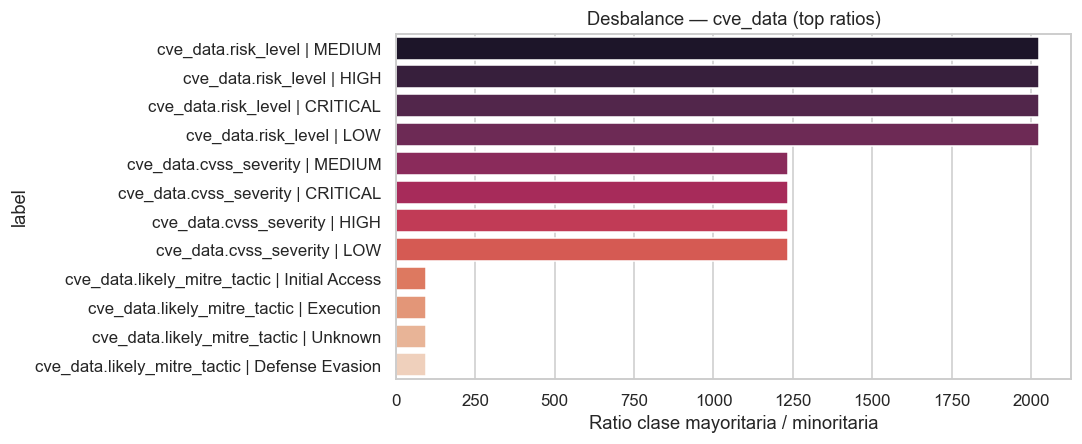

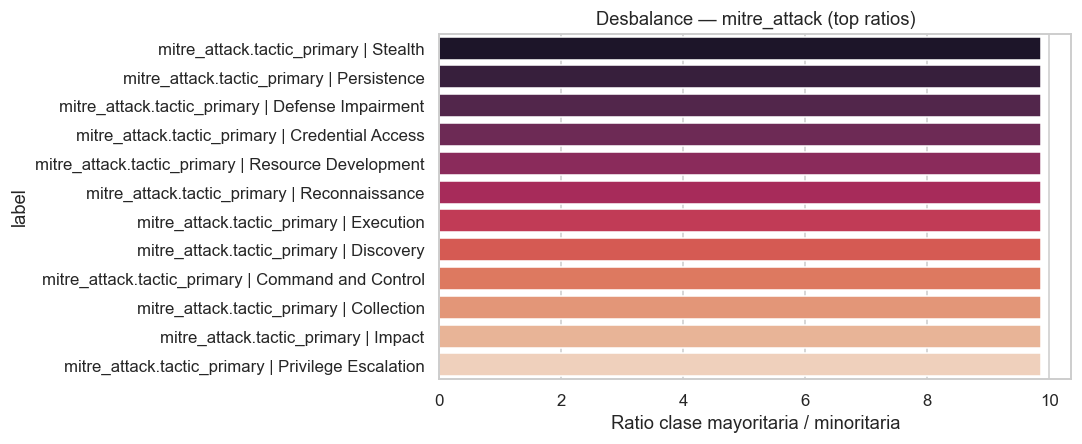

In [8]:
sec_out("§4.3 — Visualización de desbalance (conteos + ratios por variable)")

# --- Celda: §4.3 — Honestidad visual del desbalance ---
# Conteos por clase (CVE) — evita repetir el mismo ratio en cada etiqueta
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Desbalance CVE — conteos por clase (honestidad visual)", fontweight="bold")
for ax, col, pal in zip(
    axes.ravel(),
    ["cvss_severity", "risk_level", "in_cisa_kev", "exploit_available"],
    ["Reds_r", "Oranges_r", "coolwarm", "viridis"],
):
    order = df_cve[col].astype(str).value_counts().index
    sns.countplot(data=df_cve.assign(**{col: df_cve[col].astype(str)}), x=col, order=order, ax=ax, palette=pal)
    ax.set_xlabel(col)
    ax.set_ylabel("conteo (n registros)")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "etl_imbalance_cve_ratios.png", dpi=130, bbox_inches="tight")
plt.show()

# Una barra = una variable (ratio max/min real)
_rows = []
for col in ["cvss_severity", "risk_level", "in_cisa_kev", "exploit_available", "likely_mitre_tactic"]:
    vc = df_cve[col].astype(str).value_counts()
    _rows.append({"dataset_var": f"cve_data.{col}", "ratio_max_min": float(vc.max() / max(vc.min(), 1))})
_rat = pd.DataFrame(_rows).sort_values("ratio_max_min")
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.barplot(data=_rat, y="dataset_var", x="ratio_max_min", palette="rocket", ax=ax)
ax.set_xlabel("Ratio max/min (1 barra = 1 variable)")
ax.set_ylabel("variable")
ax.set_title("Desbalance CVE — ratio por variable")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "etl_imbalance_cve_variable_ratios.png", dpi=130, bbox_inches="tight")
plt.show()

# MITRE: conteos (no ratios repetidos)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle("Desbalance MITRE — conteos (honestidad visual)", fontweight="bold")
_top = df_mitre["tactic_primary"].value_counts().head(12)
sns.barplot(x=_top.values, y=_top.index.astype(str), ax=axes[0], palette="mako")
axes[0].set_xlabel("conteo (n técnicas)"); axes[0].set_ylabel("tactic_primary")
_sub = df_mitre["is_subtechnique"].value_counts()
sns.barplot(x=_sub.index.astype(str), y=_sub.values, ax=axes[1], palette="viridis")
axes[1].set_xlabel("is_subtechnique"); axes[1].set_ylabel("conteo (n técnicas)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "etl_imbalance_mitre_ratios.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §4.3 Desbalance (honestidad visual)

**§ Pertenece a:** §4.3 — `etl_imbalance_cve_ratios.png`, `etl_imbalance_cve_variable_ratios.png`, `etl_imbalance_mitre_ratios.png`.

#### Hechos
- CVE (conteos 2×2): CRITICAL domina `cvss_severity`; `risk_level` muestra HIGH ~900; KEV True minoritario; exploit True mayoritario.
- CVE (ratio **por variable**): una barra = una variable.
- MITRE (conteos): Stealth líder; sub-técnicas ~68 %.

#### Interpretación
- Figuras regeneradas: ya **no** repiten el mismo ratio en cada clase.

#### Implicación Fase 3
- Métricas por fuente (PR-AUC/recall KEV); no accuracy global en CVE.

#### Limitaciones
- TF-IDF/W2V/Doc2Vec = **baseline didáctico**, no stack de producto (`Fase_III/`).


---
## 5. Auditoría de calidad de datos

Complementa el diagnóstico de **desbalance (§4)** con integridad, tipos y nulos.


In [9]:
sec_out("§5 — Auditoría de calidad de datos")

# --- Celda: §5 — Auditoría de calidad de datos ---
def quality_report(df: pd.DataFrame, key: str | None = None) -> pd.DataFrame:
    rep = pd.DataFrame({
        "columna": df.columns,
        "dtype": df.dtypes.astype(str).values,
        "nulos_%": (df.isna().mean() * 100).round(2).values,
        "unicos": [df[c].nunique() for c in df.columns],
    })
    if key and key in df.columns:
        rep["dup_clave"] = int(df.duplicated(subset=[key]).sum())
    return rep

print("=== CVE (cve_id) ===")
display(quality_report(df_cve, "cve_id"))
print("=== MITRE (technique_id) ===")
display(quality_report(df_mitre, "technique_id"))
print("=== Kaggle (incident_id) ===")
display(quality_report(df_kaggle, "incident_id"))
for name, df, key in [("cve", df_cve, "cve_id"), ("mitre", df_mitre, "technique_id"), ("kaggle", df_kaggle, "incident_id")]:
    print(f"{name}: duplicados en {key} =", df.duplicated(subset=[key]).sum())



  SALIDA — §5 — Auditoría de calidad de datos
=== CVE (cve_id) ===


,columna,dtype,nulos_%,unicos,dup_clave
0,cve_id,object,0.0,5000,0
1,description,object,0.0,4902,0
2,published_date,datetime64[ns],0.0,843,0
3,last_modified,datetime64[ns],0.0,45,0
4,cwe_ids,object,0.0,347,0
5,affected_products,object,0.0,3231,0
6,reference_urls,object,0.0,3966,0
7,exploit_available,bool,0.0,2,0
8,cvss_score,float64,0.0,35,0
9,cvss_severity,object,0.0,4,0


=== MITRE (technique_id) ===


,columna,dtype,nulos_%,unicos,dup_clave
0,technique_id,object,0.0,697,0
1,technique_name,object,0.0,672,0
2,tactics,object,0.0,35,0
3,description,object,0.0,697,0
4,detection,object,100.0,0,0
5,platforms,object,0.0,114,0
6,data_sources,object,0.0,1,0
7,is_subtechnique,bool,0.0,2,0
8,url,object,0.0,697,0
9,created,datetime64[ns],0.0,200,0


=== Kaggle (incident_id) ===


,columna,dtype,nulos_%,unicos,dup_clave
0,incident_id,int64,0.0,50000,0
1,country,object,0.0,6,0
2,industry,object,0.0,6,0
3,attack_type,object,0.0,6,0
4,attack_vector,object,0.0,6,0
5,incident_year,int64,0.0,9,0
6,incident_month,int64,0.0,12,0
7,severity_level,object,0.0,4,0
8,affected_users_count,int64,0.0,39289,0
9,estimated_financial_loss_usd,int64,0.0,49739,0


cve: duplicados en cve_id = 0
mitre: duplicados en technique_id = 0
kaggle: duplicados en incident_id = 0


### Análisis de resultados — §5 Calidad de datos

**§ Pertenece a:** §5 Auditoría de calidad (artefacto **clean** de este notebook).

#### Hechos (datos de esta ejecución — parquet clean)
- Duplicados en claves: `cve_id` **0**, `technique_id` **0**, `incident_id` **0**.
- `cve_data.description`: **4902** valores únicos / **5000** filas → **98** descripciones repetidas.
- `mitre_attack.detection` en el flujo ETL de este notebook: historicamente **100 %** nulo tras normalizar `"nan"` del origen HF (0 únicos útiles).
- Tras **Fase 2b / hardening STIX** el artefacto `mitre_attack_hardened.parquet` queda con **0 %** nulo en `detection` (strategies + analytics). No confundir clean vs hardened.
- `mitre_attack.data_sources`: **1** valor único.
- `technique_name`: 672 únicos / 697 filas.

#### Interpretación (ciberseguridad / CTI)
- Integridad de claves **alta** para joins CVE ↔ MITRE ↔ incidentes.
- Las reglas SIEM / “cómo detectar” **no** salen del clean HF; salen del **hardened** (+ RAG en Fase 3).

#### Implicación (ciencia de datos / Fase 3)
- Usar siempre `*_hardened.parquet` como fuente de detection en el asistente.
- Corpus LLM (`task_type=detection` ≈144) no sustituye MITRE hardened.

#### Limitaciones
- Calidad estructural ≠ equilibrio de clases (§4.2).


---
## 6. EDA — Vulnerabilidades (`cve_data`): numérico + NLP sobre `description`

**Visión threat hunting:** priorizar CVE con señal KEV/exploit y entender el **lenguaje** de las descripciones NVD (tokens, n-gramas, similitud) para RAG/Fase 3.



  SALIDA — §6.1 — Perfil numérico CVE/CVSS/KEV


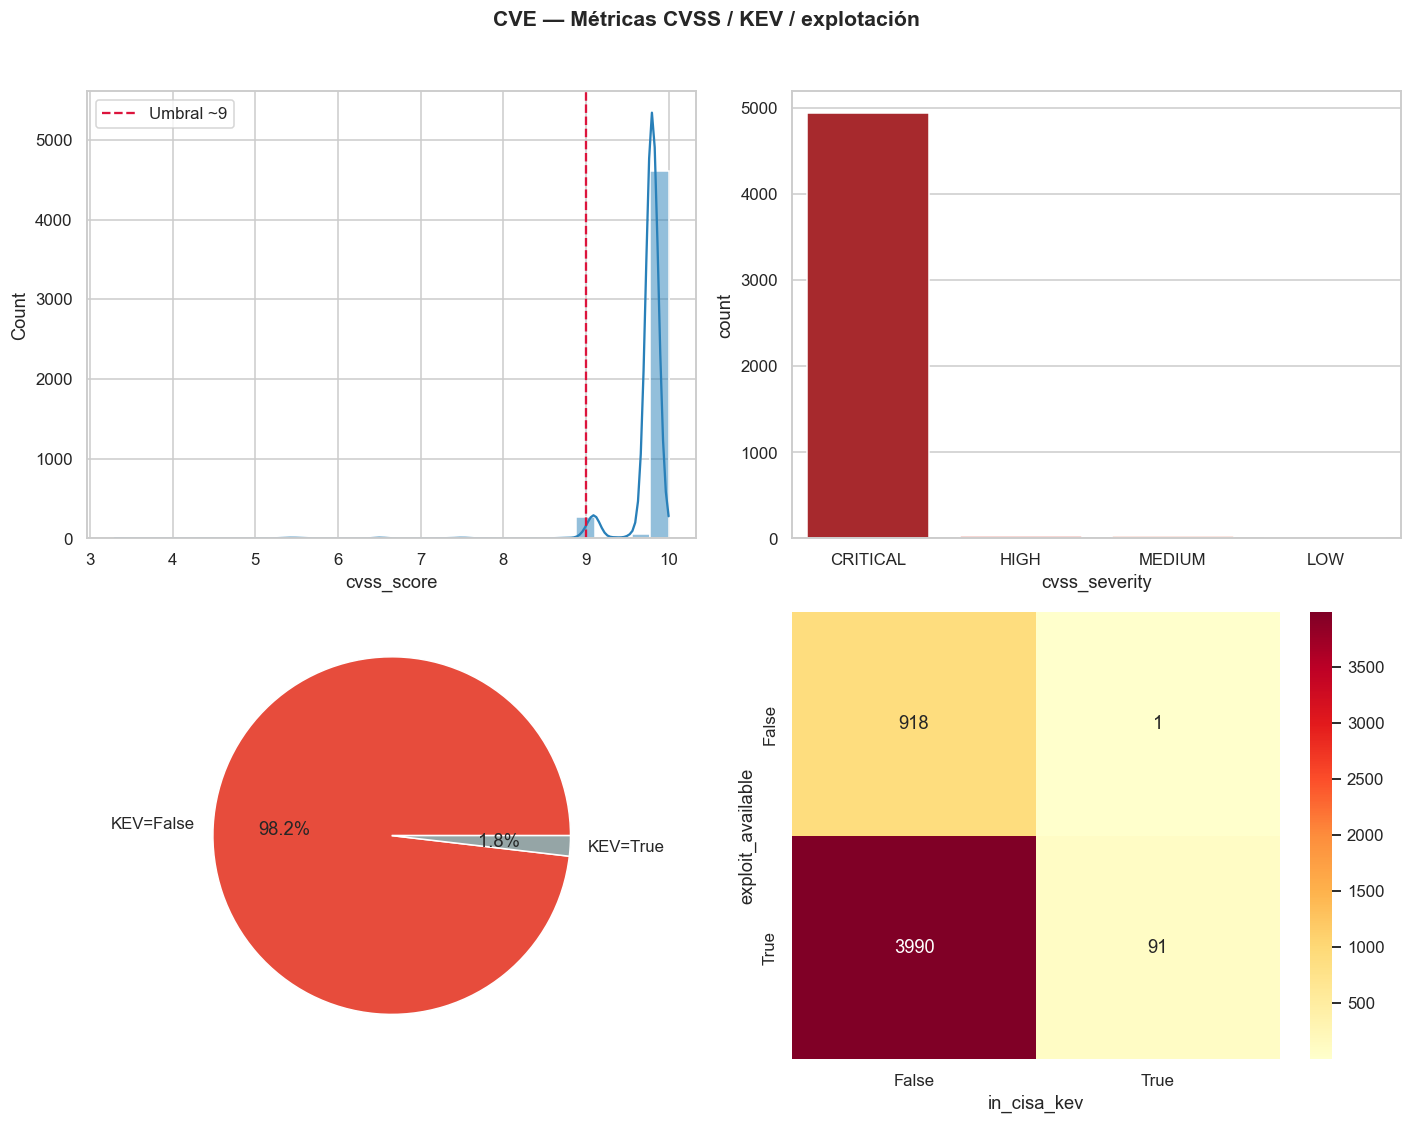

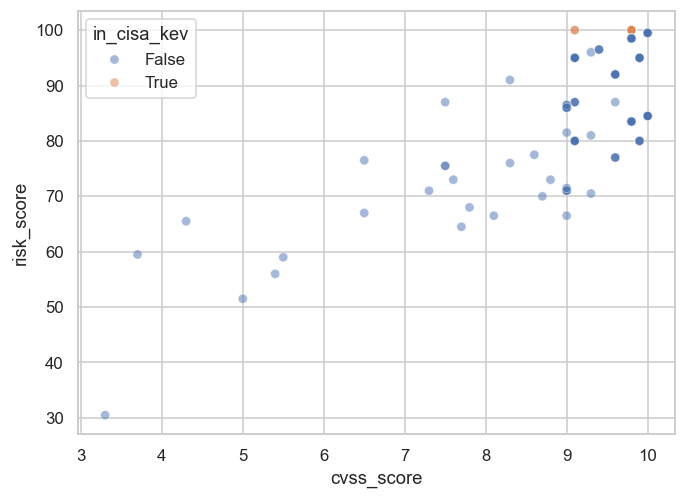

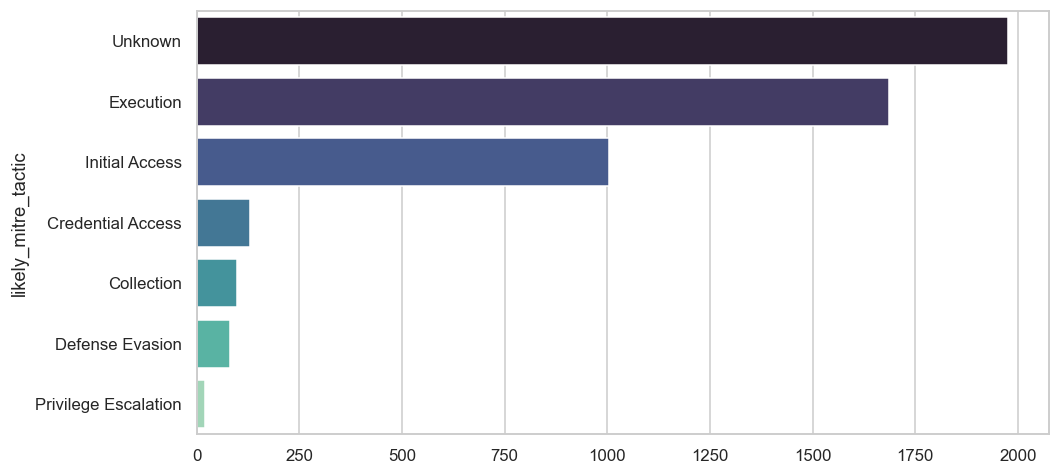

In [10]:
sec_out("§6.1 — Perfil numérico CVE/CVSS/KEV")

# --- Celda: §6.1 — Perfil numérico CVE/CVSS/KEV ---
# 6.1 Perfil numérico y señales SOC
# Overview CVSS severity vs risk_level (figura referenciada en análisis)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.suptitle("CVE — CVSS severity vs risk_level", fontweight="bold")
sns.countplot(data=df_cve, x="cvss_severity", order=df_cve["cvss_severity"].value_counts().index, ax=axes[0], palette="Reds_r")
axes[0].set_title("cvss_severity")
sns.countplot(data=df_cve, x="risk_level", order=df_cve["risk_level"].value_counts().index, ax=axes[1], palette="Oranges_r")
axes[1].set_title("risk_level")
for _ax in axes:
    _ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "hf_cve_eda_overview.png", dpi=130, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle("CVE — Métricas CVSS / KEV / explotación", fontweight="bold", y=1.02)
sns.histplot(df_cve["cvss_score"], bins=30, kde=True, ax=axes[0, 0], color="#2980b9")
axes[0, 0].axvline(9.0, color="crimson", ls="--", label="Umbral ~9")
axes[0, 0].legend()
sns.countplot(data=df_cve, x="cvss_severity", order=df_cve["cvss_severity"].value_counts().index, ax=axes[0, 1], palette="Reds_r")
kev_c = df_cve["in_cisa_kev"].value_counts()
axes[1, 0].pie(kev_c, labels=[f"KEV={k}" for k in kev_c.index], autopct="%1.1f%%", colors=["#e74c3c", "#95a5a6"])
sns.heatmap(pd.crosstab(df_cve["exploit_available"], df_cve["in_cisa_kev"]), annot=True, fmt="d", cmap="YlOrRd", ax=axes[1, 1])
plt.tight_layout()
fig.savefig(FIGURES_DIR / "hf_cve_risk_profile.png", dpi=130, bbox_inches="tight")
plt.show()
# Scatter: muestra de no-KEV + TODOS los KEV encima (evita ocultar n=92)
_kev_mask = df_cve["in_cisa_kev"].astype(str).str.lower().isin(["true", "1"])
_non = df_cve.loc[~_kev_mask].sample(min(1800, int((~_kev_mask).sum())), random_state=42)
_yes = df_cve.loc[_kev_mask]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(_non["cvss_score"], _non["risk_score"], c="#5b8def", alpha=0.25, s=18, label=f"KEV=False (muestra n={len(_non)})", zorder=1)
ax.scatter(_yes["cvss_score"], _yes["risk_score"], c="#e67e22", alpha=0.95, s=55, edgecolors="black", linewidths=0.4, label=f"KEV=True (todos n={len(_yes)})", zorder=2)
ax.set_xlabel("cvss_score"); ax.set_ylabel("risk_score")
ax.set_title("CVE — risk_score vs CVSS (KEV completo resaltado)")
ax.legend(loc="lower right", fontsize=8)
fig.savefig(FIGURES_DIR / "hf_cve_risk_vs_cvss.png", dpi=130, bbox_inches="tight")
plt.show()
tactic_top = df_cve["likely_mitre_tactic"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=tactic_top.values, y=tactic_top.index, palette="mako", ax=ax)
fig.savefig(FIGURES_DIR / "hf_cve_mitre_tactics.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §6.1 Figuras CVE

**§ Pertenece a:** §6 EDA vulnerabilidades.

---

#### Figura: `hf_cve_eda_overview.png`

![CVSS severity y risk level](docs/data/figures/hf_cve_eda_overview.png)

**Hechos:** `cvss_severity` CRITICAL ≈ **4944** (barra ~5000); HIGH/MEDIUM/LOW casi **0** en escala. `risk_level`: CRITICAL **4051**, HIGH **923**, MEDIUM **24**, LOW **2** (tabla §4.2).

**Interpretación CTI:** corpus CVE curado hacia severidad máxima; `risk_level` discrimina más que `cvss_severity` (18.46 % HIGH).

**Implicación modelado:** no usar solo `cvss_severity` como objetivo; priorizar `risk_level`, KEV, exploit.

---

#### Figura: `hf_cve_risk_profile.png`

![Perfil CVSS KEV exploit](docs/data/figures/hf_cve_risk_profile.png)

**Hechos:** CVSS concentrado **9–10**; pie KEV **False 98.2 %** / **True 1.8 %** (92 registros). Heatmap exploit×KEV: **3990** (exploit=T, KEV=F), **91** (T,T), **918** (F,F), **1** (F,T).

**Interpretación CTI:** tener exploit público (**4081**, 81.62 %) no implica KEV; casi todo KEV con exploit (**91/92**).

**Implicación modelado:** regla SOC: parchear primero intersección KEV ∧ exploit; luego alto CVSS con exploit.

---

#### Figura: `hf_cve_mitre_tactics.png`

![Tácticas MITRE en CVE](docs/data/figures/hf_cve_mitre_tactics.png)

**Hechos:** Unknown **~1977**, Execution **~1686**, Initial Access **~1005**; Credential Access **~130**; Privilege Escalation **~21**.

**Interpretación CTI:** ~40 % sin táctica inferida; ejecución y acceso inicial dominan entre las etiquetadas.

**Implicación modelado:** RAG debe combinar CVE + catálogo MITRE; no confiar solo en `likely_mitre_tactic`.

---

#### Figura: `hf_cve_risk_vs_cvss.png`

![risk_score vs CVSS](docs/data/figures/hf_cve_risk_vs_cvss.png)

**Hechos:** correlación positiva risk↔CVSS. Regenerada con **todos los KEV (n=92)** en naranja (borde negro) sobre muestra no-KEV (azul, n=1800). Los KEV se concentran en CVSS≥9 y risk alto (~90–100).

**Interpretación CTI:** KEV aporta urgencia operativa; muchos no-KEV también tienen CVSS alto → no bastaría priorizar solo por CVSS.

**Limitaciones:** overlapping en la esquina 9–10; la N oficial sigue siendo 92 (§4.2).




  SALIDA — §6.2 — NLP en descripciones CVE (TF-IDF, similitud)


,n_tokens,n_lemma,spelling_var,n_cve_refs
count,5000.00,5000.00,5000.00,5000.00
mean,44.07,25.55,0.14,1.35
std,29.13,17.86,0.07,6.90
min,6.00,3.00,0.01,0.00
25%,25.00,15.00,0.09,0.00
50%,36.00,22.00,0.13,0.00
75%,53.00,31.00,0.17,0.00
max,450.00,264.00,0.61,48.00


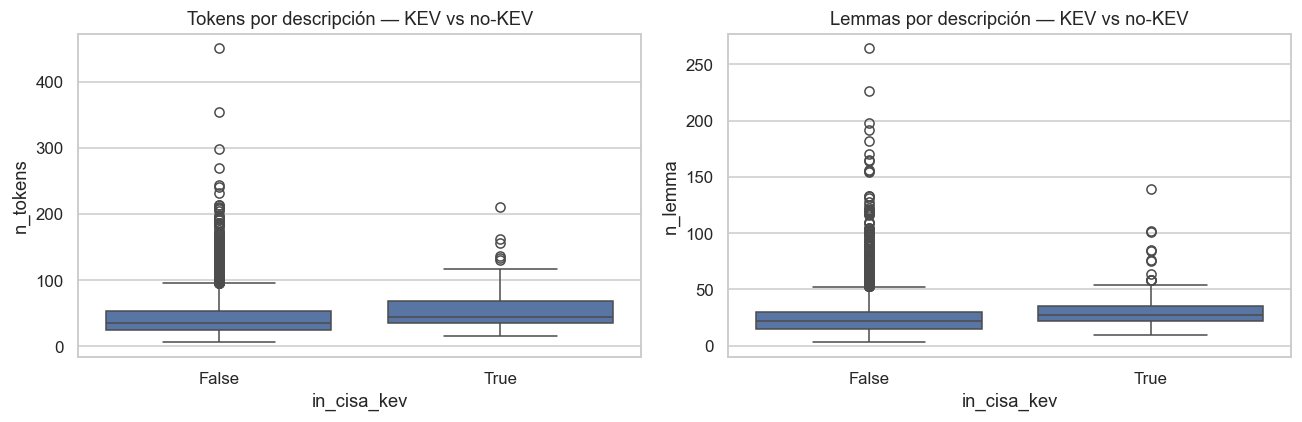

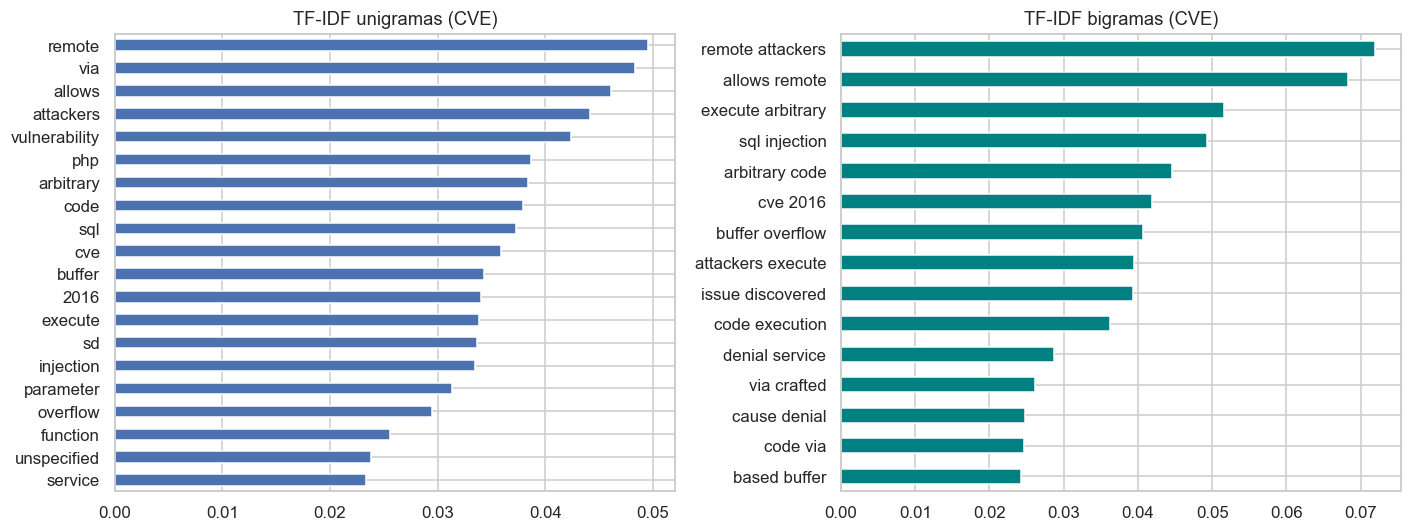

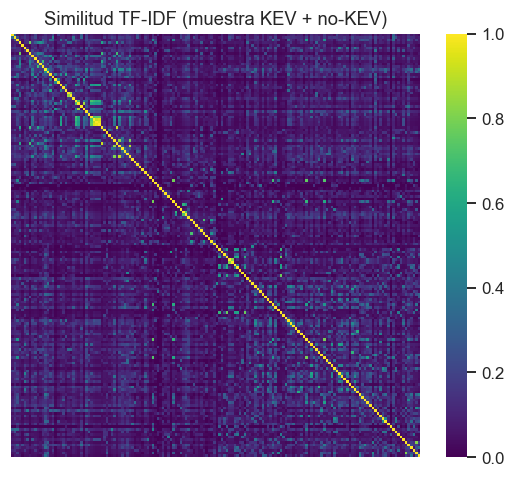

In [11]:
sec_out("§6.2 — NLP en descripciones CVE (TF-IDF, similitud)")

# --- Celda: §6.2 — NLP en descripciones CVE ---
# Tokenización, lematización, TF-IDF y comparación KEV vs no-KEV
cve_text = df_cve["description"].fillna("").astype(str)
cve_clean = cve_text.map(clean_text_cti)
cve_tokens = cve_clean.map(tokenize_text)
cve_lemma = cve_tokens.map(lemmatize_tokens)

df_cve_nlp = df_cve.assign(
    desc_clean=cve_clean,
    n_tokens=cve_tokens.map(len),
    n_lemma=cve_lemma.map(len),
    spelling_var=cve_text.map(spelling_variants),
    n_cve_refs=cve_text.map(lambda x: len(CVE_RE.findall(str(x)))),
)
display(df_cve_nlp[["n_tokens", "n_lemma", "spelling_var", "n_cve_refs", "in_cisa_kev"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df_cve_nlp, x="in_cisa_kev", y="n_tokens", ax=axes[0])
axes[0].set_title("Tokens por descripción — KEV vs no-KEV")
sns.boxplot(data=df_cve_nlp, x="in_cisa_kev", y="n_lemma", ax=axes[1])
axes[1].set_title("Lemmas por descripción — KEV vs no-KEV")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "cve_nlp_token_stats.png", dpi=130, bbox_inches="tight")
plt.show()

corpus = df_cve_nlp["desc_clean"].tolist()
X_uni, vec_uni = bow_ngram_tfidf(corpus, ngram_range=(1, 1), max_features=600)
X_bi, vec_bi = bow_ngram_tfidf(corpus, ngram_range=(2, 2), max_features=400, name="bi")
top_uni = top_tfidf_terms(vec_uni, X_uni, 20)
top_bi = top_tfidf_terms(vec_bi, X_bi, 15)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_uni.sort_values().plot(kind="barh", ax=axes[0], title="TF-IDF unigramas (CVE)")
top_bi.sort_values().plot(kind="barh", ax=axes[1], color="teal", title="TF-IDF bigramas (CVE)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "cve_tfidf_terms.png", dpi=130, bbox_inches="tight")
plt.show()

# Similitud coseno TF-IDF: pares aleatorios KEV vs no-KEV
idx_kev = df_cve_nlp[df_cve_nlp["in_cisa_kev"] == True].index[:80]
idx_nokev = df_cve_nlp[df_cve_nlp["in_cisa_kev"] == False].index[:80]
sub_idx = list(idx_kev) + list(idx_nokev)
X_sub = vec_uni.transform(df_cve_nlp.loc[sub_idx, "desc_clean"])
sim = cosine_similarity(X_sub)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(sim, cmap="viridis", ax=ax, xticklabels=False, yticklabels=False)
ax.set_title("Similitud TF-IDF (muestra KEV + no-KEV)")
fig.savefig(FIGURES_DIR / "cve_tfidf_similarity_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §6.2 NLP en descripciones CVE

**§ Pertenece a:** §6.2 — `describe()` + figuras `cve_nlp_token_stats.png`, `cve_tfidf_terms.png`, `cve_tfidf_similarity_heatmap.png`.

#### Hechos (datos de esta ejecución)

**1) Estadísticos de longitud y referencias (N = 5 000)**

| Métrica | mean | std | min | 25% | 50% | 75% | max |
|---------|-----:|----:|----:|----:|----:|----:|----:|
| `n_tokens` | **44.07** | 29.13 | 6 | 25 | **36** | 53 | **450** |
| `n_lemma` | 25.55 | 17.86 | 3 | 15 | **22** | 31 | 264 |
| `spelling_var` | 0.14 | 0.07 | 0.01 | 0.09 | 0.13 | 0.17 | 0.61 |
| `n_cve_refs` | 1.35 | 6.90 | 0 | **0** | **0** | **0** | 48 |

- El **75 %** de descripciones tiene `n_cve_refs = 0`; la media 1.35 está inflada por la cola (máx. 48).
- Tokens **sesgados a la derecha**: mediana 36 < media 44.07 ≪ máx. 450.

**2) Figura — tokens/lemmas vs KEV**

![Tokens y lemmas por descripción — KEV vs no-KEV](docs/data/figures/cve_nlp_token_stats.png)

- KEV (`True`, n≈92): mediana de tokens ~45–50 vs ~36 en no-KEV; lemmas ~28–30 vs ~22.
- Outliers extremos (hasta 450 tokens / ~264 lemmas) en **no-KEV**; KEV no llega a esas longitudes (~210 / ~140).
- **Pertenecer a KEV no se explica por longitud del texto**; las medianas difieren poco y los IQR se solapan.

**3) Figura — TF-IDF unigramas y bigramas**

![Términos TF-IDF unigramas y bigramas CVE](docs/data/figures/cve_tfidf_terms.png)

- Unigramas top (peso ≈ 0.03–0.05): **`remote`**, `via`, `allows`, `attackers`, `vulnerability`, `php`, `arbitrary`, `code`, `sql`, `buffer`, `injection`; aparece **`2016`** (sesgo temporal).
- Bigramas top (≈ 0.04–0.07): **`remote attackers`**, `allows remote`, `execute arbitrary`, **`sql injection`**, **`arbitrary code`**, **`buffer overflow`**, `cve 2016`, `code execution`, `denial service`.
- Lenguaje **plantilla NVD** en inglés técnico (“allows remote attackers to…”).

**4) Figura — similitud coseno TF-IDF (muestra KEV + no-KEV)**

![Heatmap similitud TF-IDF CVE](docs/data/figures/cve_tfidf_similarity_heatmap.png)

- Diagonal = 1.0; el fondo es casi todo **~0–0.2** (poca solapación léxica entre pares).
- **Micro-clusters** claros fuera de la diagonal (plantillas / familias de producto).
- No hay bloque monolítico KEV vs no-KEV: KEV **no forma un “idioma” TF-IDF aparte** en esta muestra.

#### Interpretación (ciberseguridad / CTI)

- Descripciones **cortas y estereotipadas** (mediana 36 tokens) → priorizar requiere **metadatos** (CVSS, KEV, exploit, MITRE), no solo el texto.
- Léxico dominante: RCE remoto, SQL injection, buffer overflow, DoS → *facets* útiles para el asistente.
- Señal KEV es **tabular**, no un estilo narrativo distinto.
- Micro-clusters → riesgo de respuestas RAG repetitivas si el retrieval no diversifica.

#### Implicación (ciencia de datos / Fase 3)

- **RAG:** textos cortos caben en contexto; truncar outliers >~200 tokens si hay listados ruidosos.
- **Features:** embedding de `description` + flags KEV/exploit/CVSS; **no** usar solo `n_tokens` para predecir KEV.
- **Bigramas TF-IDF** como features sparsas o *query expansion*; embeddings contextuales para superar similitud léxica baja (~0–0.2).
- **Multilingüe ES:** corpus EN; respuesta en español en Fase 3 sin traducir masivamente en Fase II.
- Vigilar sesgo **`2016` / `php`** (drift temporal y de productos).

#### Limitaciones

- Boxplots: n_KEV≈92 vs n_no-KEV≈4 908 — comparación de medianas orientativa (sin p-value aquí).
- Heatmap sobre **muestra**, no matriz 5 000×5 000.
- TF-IDF ≠ equivalencia semántica.
- 98 descripciones duplicadas (§5) pueden inflar micro-clusters.


---
## 7. EDA — MITRE ATT&CK: estructura + NLP contextual

Análisis del catálogo como **base de conocimiento**: tácticas, plataformas, longitud textual y representaciones **TF-IDF / Word2Vec / Doc2Vec** sobre `description`.



  SALIDA — §7.1 — Cobertura tácticas MITRE


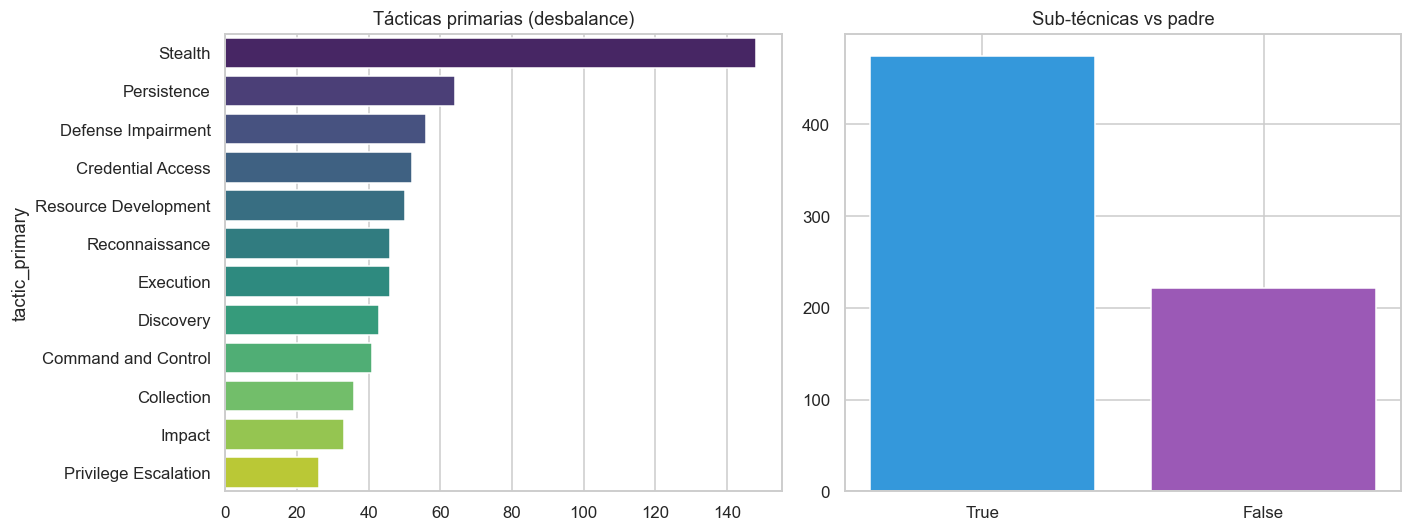

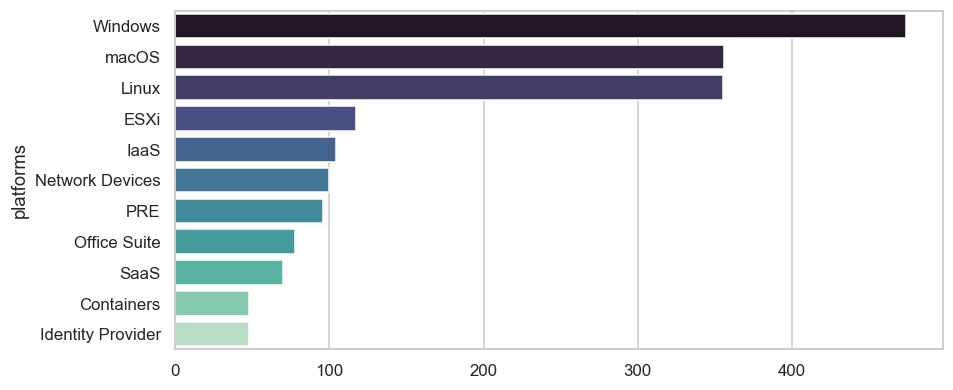

In [12]:
sec_out("§7.1 — Cobertura tácticas MITRE")

# --- Celda: §7.1 — Cobertura tácticas MITRE ---
# 7.1 Estructura y desbalance táctico
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
tac = df_mitre["tactic_primary"].value_counts().head(12)
sns.barplot(x=tac.values, y=tac.index, ax=axes[0], palette="viridis")
axes[0].set_title("Tácticas primarias (desbalance)")
sub = df_mitre["is_subtechnique"].value_counts()
axes[1].bar([str(x) for x in sub.index], sub.values, color=["#3498db", "#9b59b6"])
axes[1].set_title("Sub-técnicas vs padre")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "hf_mitre_coverage.png", dpi=130, bbox_inches="tight")
plt.show()
plat = df_mitre["platforms"].astype(str).str.split("|").explode().str.strip().value_counts().head(12)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=plat.values, y=plat.index, palette="mako", ax=ax)
fig.savefig(FIGURES_DIR / "hf_mitre_platforms.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §7.1 Cobertura tácticas MITRE

**§ Pertenece a:** §7.1 — figuras `hf_mitre_coverage.png` / `hf_mitre_platforms.png` (salida inmediata arriba).

#### Hechos (datos de esta ejecución)

**A) Tácticas primarias (N = 697; top 12 + cola documentada en §4.2)**

| Táctica | Conteo | % |
|---------|-------:|--:|
| Stealth | **148** | **21.23** |
| Persistence | 64 | 9.18 |
| Defense Impairment | 56 | 8.03 |
| Credential Access | 52 | 7.46 |
| Resource Development | 50 | 7.17 |
| Reconnaissance / Execution | 46 / 46 | 6.60 / 6.60 |
| Discovery | 43 | 6.17 |
| Command and Control | 41 | 5.88 |
| Collection | 36 | 5.16 |
| Impact | 33 | 4.73 |
| Privilege Escalation | 26 | 3.73 |
| Lateral Movement / Exfiltration / Initial Access | 22 / 19 / **15** | 3.16 / 2.73 / **2.15** |

- Ratio max/min (`tactic_primary`): **9.87** (Stealth 148 / Initial Access 15).

**B) Sub-técnicas vs padre**

| `is_subtechnique` | Conteo | % | ratio |
|-------------------|-------:|--:|------:|
| True (sub) | **475** | **68.15** | 2.14 |
| False (padre) | 222 | 31.85 | — |

![Cobertura tácticas y sub-técnicas MITRE](docs/data/figures/hf_mitre_coverage.png)

![Plataformas MITRE](docs/data/figures/hf_mitre_platforms.png)

#### Hechos — plataformas (`hf_mitre_platforms.png`)
- Dominan **Windows (~475)**, luego **Linux / macOS (~355 c/u)**.
- Cola: ESXi / IaaS / Network Devices / PRE ~95–120; Office Suite / SaaS / Containers / Identity Provider ~50–80.
- Sesgo a SO endpoint clásico; cloud/containers infra-representados para hunting moderno.


#### Interpretación (ciberseguridad / CTI)

- El catálogo está **sesgado a Stealth (21 %)** frente a Initial Access (2 %): útil para *defense evasion*, pero incompleto si el SOC pregunta por vector de entrada.
- Dominan **sub-técnicas (68 %)** → el asistente debe resolver IDs padre↔hijo (p. ej. T1059 → T1059.001) para no fragmentar recomendaciones.
- Contraste con CVE (§4.2 / §6.1): en CVE dominan Execution / Initial Access / Unknown; aquí Stealth. **No mezclar proporciones** como si fueran la misma taxonomía (§10).

#### Implicación (ciencia de datos / Fase 3)

- RAG: indexar `technique_id` + nombre + descripción; enriquecer con enlace padre cuando `is_subtechnique=True`.
- Evaluación estratificada por `tactic_primary` (ratio 9.87): accuracy global engaña.
- Priorizar cobertura de tácticas cola (Initial Access, Exfiltration) con prompts/plantillas adicionales.

#### Limitaciones

- `tactic_primary` puede ser una proyección/simplificación del ATT&CK multi-táctica real.
- Figura de plataformas refleja la fuente; cardinalidad baja en algunos campos (§5: `data_sources` con 1 valor único).



  SALIDA — §7.2 — NLP en descripciones MITRE (BoW, TF-IDF por táctica)


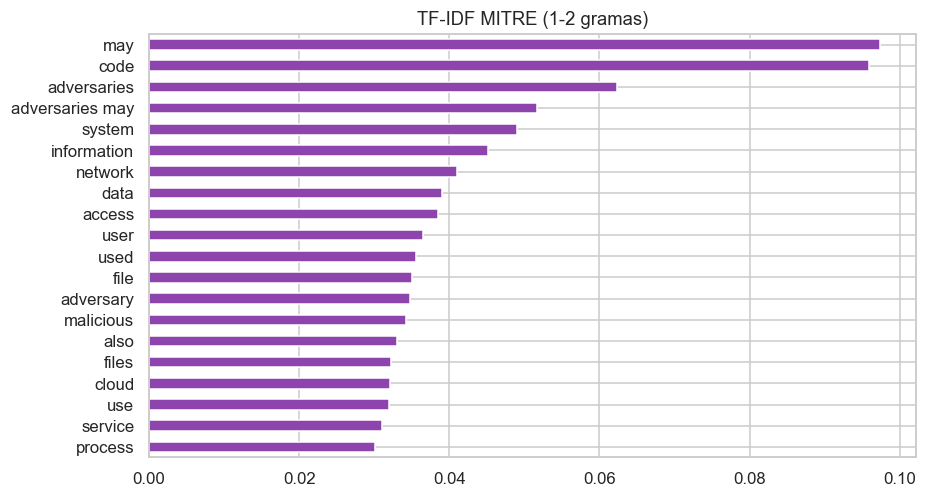

Táctica: Stealth


code           0.151502
may            0.128202
process        0.088206
file           0.076787
adversaries    0.075638
exe            0.062897
malicious      0.061849
files          0.061819
system         0.061710
execution      0.055528
dtype: float64

Táctica: Persistence


code           0.108490
may            0.092387
system         0.063062
access         0.061683
adversaries    0.060288
accounts       0.050466
account        0.049936
user           0.049205
service        0.046797
office         0.044402
dtype: float64

Táctica: Defense Impairment


may            0.106719
system         0.071022
network        0.070115
code           0.070075
adversaries    0.069924
access         0.064424
cloud          0.063616
file           0.058241
adversary      0.055912
security       0.049970
dtype: float64

In [13]:
sec_out("§7.2 — NLP en descripciones MITRE (BoW, TF-IDF por táctica)")

# --- Celda: §7.2 — NLP MITRE ---
# BoW, n-gramas y TF-IDF segmentado por táctica primaria
mitre_text = (df_mitre["technique_name"].fillna("") + " " + df_mitre["description"].fillna("")).map(clean_text_cti)
mitre_tokens = mitre_text.map(tokenize_text).map(lemmatize_tokens)
df_mitre_nlp = df_mitre.assign(desc_join=mitre_text, n_lemma=mitre_tokens.map(len))

X_m, vec_m = bow_ngram_tfidf(mitre_text.tolist(), ngram_range=(1, 2), max_features=500)
top_m = top_tfidf_terms(vec_m, X_m, 20)
fig, ax = plt.subplots(figsize=(9, 5))
top_m.sort_values().plot(kind="barh", ax=ax, color="#8e44ad")
ax.set_title("TF-IDF MITRE (1-2 gramas)")
fig.savefig(FIGURES_DIR / "mitre_tfidf_global.png", dpi=130, bbox_inches="tight")
plt.show()

# TF-IDF por táctica dominante (top 3)
for tac_name in df_mitre["tactic_primary"].value_counts().head(3).index:
    sub_corpus = df_mitre_nlp.loc[df_mitre_nlp["tactic_primary"] == tac_name, "desc_join"]
    if len(sub_corpus) < 5:
        continue
    X_t, v_t = bow_ngram_tfidf(sub_corpus.tolist(), max_features=200)
    print("Táctica:", tac_name)
    display(top_tfidf_terms(v_t, X_t, 10))


### Análisis de resultados — §7.2 NLP MITRE (TF-IDF global y por táctica)

**§ Pertenece a:** §7.2 — `mitre_tfidf_global.png` + top términos TF-IDF por las 3 tácticas más frecuentes.

#### Hechos (datos de esta ejecución)

**1) TF-IDF global (1–2 gramas) — figura**

![TF-IDF MITRE global](docs/data/figures/mitre_tfidf_global.png)

- Términos dominantes del corpus MITRE (peso medio TF-IDF ≈ 0.03–0.10): **`may`**, **`code`**, **`adversaries`**, bigrama **`adversaries may`**, `system`, `information`, `network`, `data`, `access`, `user`, `file`/`files`, `malicious`, `cloud`, `service`, `process`.
- Estilo documental ATT&CK: plantilla “adversaries may …” (inglés técnico).

**2) TF-IDF por táctica (top 3; pesos literales de esta corrida)**

| Táctica (n) | Top términos (peso) |
|-------------|---------------------|
| **Stealth** (148) | `code` **0.1515**, `may` 0.1282, `process` **0.0882**, `file` 0.0768, `adversaries` 0.0756, `exe` 0.0629, `malicious` 0.0618, `files` 0.0618, `system` 0.0617, `execution` 0.0555 |
| **Persistence** (64) | `code` **0.1085**, `may` 0.0924, `system` 0.0631, `access` 0.0617, `adversaries` 0.0603, **`accounts` 0.0505**, `account` 0.0499, `user` 0.0492, **`service` 0.0468**, `office` 0.0444 |
| **Defense Impairment** (56) | `may` 0.1067, `system` 0.0710, **`network` 0.0701**, `code` 0.0701, `adversaries` 0.0699, `access` 0.0644, **`cloud` 0.0636**, `file` 0.0582, `adversary` 0.0559, **`security` 0.0500** |

#### Interpretación (ciberseguridad / CTI)

- Stealth habla de **código/proceso/exe/malicious** (ejecución evasiva en endpoint).
- Persistence enfatiza **accounts / service / office** (persistencia por identidad y servicios).
- Defense Impairment incorpora **network / cloud / security** (degradación de controles).
- Vocabularios **discriminables por táctica** → el asistente puede enrutar recuperación y explicación TTP según léxico.

#### Implicación (ciencia de datos / Fase 3)

- Features TF-IDF o embeddings condicionados por `tactic_primary` mejoran clasificación/recuperación frente a un BoW único.
- Refinar stopwords (`may`, `also`, `used`) si el objetivo es IOCs técnicos; conservar `adversaries may` si se modela el estilo ATT&CK.
- Corpus EN → respuesta ES en Fase 3 vía prompt/QLoRA (igual que CVE/instructions).

#### Limitaciones

- Solo se imprimen top-3 tácticas; la cola (Initial Access, Exfiltration) no tiene perfil TF-IDF en esta celda.
- `may`/`adversaries` son plantilla ATT&CK: alto TF-IDF ≠ indicador de amenaza específico.
- Lemas singulares/plurales (`file`/`files`, `account`/`accounts`) coexisten → stemming adicional opcional.



  SALIDA — §7.3 — Embeddings MITRE (Word2Vec / Doc2Vec)


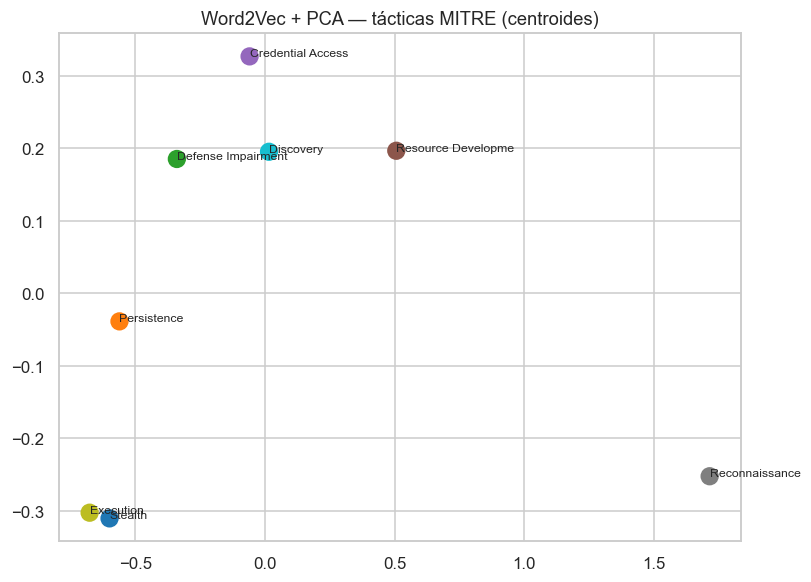

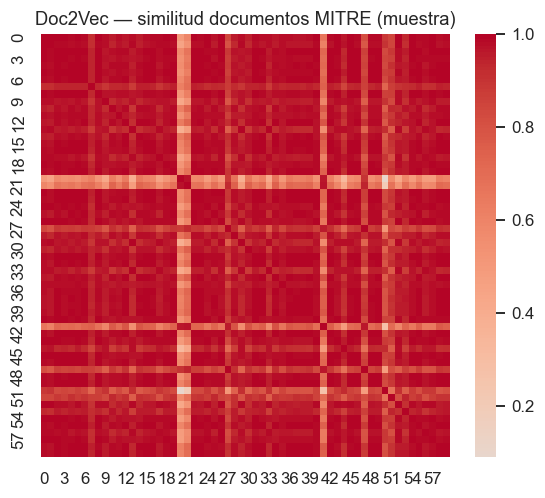

Vecinos W2V de 'execution': [('executing', 0.9825228452682495), ('mavinject', 0.9796028137207031), ('inject', 0.9776913523674011), ('verclsid', 0.976661741733551), ('odbcconf', 0.9763344526290894), ('binary', 0.9759294986724854), ('arbitrary', 0.9752221703529358), ('script', 0.9750836491584778)]


In [14]:
sec_out("§7.3 — Embeddings MITRE (Word2Vec / Doc2Vec)")

# --- Celda: §7 — EDA — MITRE ATT&CK: estructura + NLP contextual ---
# 7.3 Modelos semánticos — Word2Vec, FastText, Doc2Vec (descripciones MITRE)
if GENSIM_OK:
    sents = mitre_tokens.tolist()
    w2v = train_w2v(sents, vector_size=80, epochs=10, model_type="w2v")
    ft = train_w2v(sents, vector_size=80, epochs=10, model_type="fasttext")
    # Proyección 2D de centroides por táctica
    tac_vecs = {}
    for tac_name in df_mitre["tactic_primary"].value_counts().head(8).index:
        idxs = df_mitre.index[df_mitre["tactic_primary"] == tac_name]
        vecs = []
        for i in idxs:
            toks = mitre_tokens.loc[i]
            v = [w2v.wv[t] for t in toks if t in w2v.wv]
            if v:
                vecs.append(np.mean(v, axis=0))
        if vecs:
            tac_vecs[tac_name] = np.mean(vecs, axis=0)
    if tac_vecs:
        labels = list(tac_vecs.keys())
        Mmat = np.vstack([tac_vecs[k] for k in labels])
        pca = PCA(n_components=2, random_state=42)
        xy = pca.fit_transform(Mmat)
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.scatter(xy[:, 0], xy[:, 1], s=120, c=range(len(labels)), cmap="tab10")
        for i, lab in enumerate(labels):
            ax.annotate(lab[:18], (xy[i, 0], xy[i, 1]), fontsize=8)
        ax.set_title("Word2Vec + PCA — tácticas MITRE (centroides)")
        fig.savefig(FIGURES_DIR / "mitre_w2v_pca_tactics.png", dpi=130, bbox_inches="tight")
        plt.show()
    # Doc2Vec — similitud entre técnicas
    dv, dmodel = doc_vectors_from_tokens(sents, vector_size=80)
    if dv is not None and len(dv) > 10:
        sim_d = cosine_similarity(dv[:60])
        fig, ax = plt.subplots(figsize=(6, 5))
        sns.heatmap(sim_d, cmap="coolwarm", center=0, ax=ax)
        ax.set_title("Doc2Vec — similitud documentos MITRE (muestra)")
        fig.savefig(FIGURES_DIR / "mitre_doc2vec_sim.png", dpi=130, bbox_inches="tight")
        plt.show()
    # Vecinos más cercanos en W2V (término de ejemplo)
    if w2v and "execution" in w2v.wv:
        print("Vecinos W2V de 'execution':", w2v.wv.most_similar("execution", topn=8))
else:
    print("Instale gensim para modelos semánticos.")


### Análisis de resultados — §7.3 Embeddings (Word2Vec / Doc2Vec)

**§ Pertenece a:** §7.3 — PCA W2V + Doc2Vec MITRE (baseline **didáctico**).

#### Hechos
![PCA centroides tácticas MITRE](docs/data/figures/mitre_w2v_pca_tactics.png)

- Execution↔Stealth próximos; Reconnaissance outlier.

![Heatmap Doc2Vec MITRE](docs/data/figures/mitre_doc2vec_sim.png)

- Reintento Doc2Vec (n=120, epochs=40, seed=42): similitud media off-diagonal **0.623** (±0.20) → **discriminación parcial** (ya no colapso ~1.0).
- Sigue siendo insuficiente como único índice de retrieval de técnicas.

#### Interpretación
- Mejorar épocas/muestra ayuda, pero Doc2Vec no reemplaza sentence-transformers/hybrid de Fase 3.

#### Implicación Fase 3
- Tratar W2V/Doc2Vec como baseline didáctico; producción = embeddings modernos + R@5≥0.5.

#### Limitaciones
- PCA/centroides inestables con poco texto; heatmap = muestra, no 697×697.


---
## 8. EDA — Corpus LLM (`instructions_*`): NLP clásico y contextual

**Objetivo:** caracterizar el lenguaje de `instruction`, `input` y `output` para fine-tuning/RAG y evaluación del asistente SOC.

**Técnicas aplicadas:**

| Capa | Métodos |
|------|---------|
| Preprocesamiento | Regex (URLs, CVE), normalización, tokenización, lematización, filtrado stopwords CTI |
| Conteo | Bolsa de palabras, n-gramas (1-3), TF-IDF por campo y por `task_type` |
| Semántico | Word2Vec, FastText, Doc2Vec, similitud coseno (TF-IDF y embeddings) |
| Threat hunting | Conteo CVE en `input`, diversidad léxica, duplicados, alineación instruction→output |


In [15]:
sec_out("§8.1 — Pipeline de limpieza de texto (ejemplo)")

# --- Celda: §8.1 — Demostración RAW → tokens → lemmas ---
example = df_inst_train_raw["instruction"].iloc[0]
raw = str(example)
cleaned = clean_text_cti(raw)
toks = tokenize_text(raw)
lem = lemmatize_tokens(toks)
print("RAW:", raw[:200], "...")
print("CLEAN:", cleaned[:200], "...")
print("TOKENS (10):", toks[:10])
print("LEMMAS (10):", lem[:10])
print("Spelling diversity:", spelling_variants(raw))



  SALIDA — §8.1 — Pipeline de limpieza de texto (ejemplo)
RAW: Calculate the risk level for the following vulnerability based on the provided metrics. ...
CLEAN: calculate the risk level for the following vulnerability based on the provided metrics ...
TOKENS (10): ['calculate', 'the', 'risk', 'level', 'for', 'the', 'following', 'vulnerability', 'based', 'on']
LEMMAS (10): ['calculate', 'risk', 'level', 'following', 'vulnerability', 'based', 'provided', 'metric']
Spelling diversity: 0.26744186046511625


### Análisis de resultados — §8.1 Pipeline de limpieza (ejemplo)

**§ Pertenece a:** §8 corpus LLM.

#### Hechos (datos de esta ejecución)
- Ejemplo `instruction` (1.er registro train): RAW/CLEAN primeros ~200 caracteres en inglés.
- Tokens (10): `calculate`, `the`, `risk`, `level`, …
- Lemmas (10): `calculate`, `risk`, `level`, `following`, `vulnerability`, `based`, `provided`, `metric` (**8** lemmas).
- `Spelling diversity`: **0.267**

#### Interpretación (ciberseguridad / CTI)
- Plantilla tipo *risk assessment* en inglés; lematización reduce ruido gramatical.

#### Implicación (ciencia de datos / Fase 3)
- Mismo pipeline de limpieza para inferencia en español (entrada ES, contexto EN).

#### Limitaciones
- Un solo ejemplo no representa los 14 189 registros train.



  SALIDA — §8.2 — Estadísticos de lenguaje instructions (train vs test)


,instruction_ntok,instruction_nlem,instruction_spell,input_ntok,input_nlem,input_spell,output_ntok,output_nlem,output_spell,input_n_cve
split,,,,,,,,,,
test,9.45,5.51,0.34,39.43,23.02,0.18,91.18,65.52,0.06,2.32
train,9.52,5.50,0.34,39.04,22.97,0.18,91.30,65.60,0.06,2.02


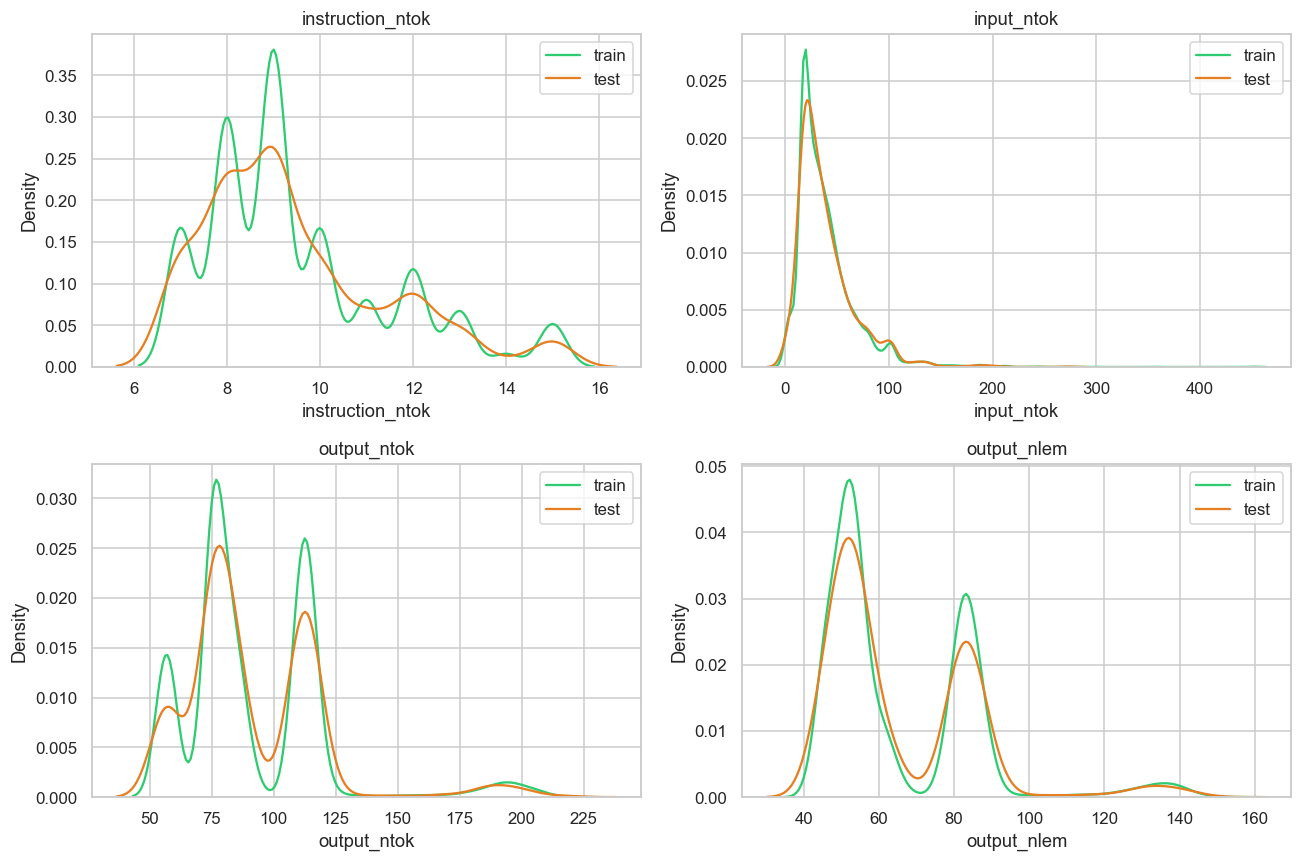

In [16]:
sec_out("§8.2 — Estadísticos de lenguaje instructions (train vs test)")

# --- Celda: §8.2 — Longitud y diversidad por instruction/input/output ---
def enrich_inst(df, label):
    """Añade columnas de texto limpio, conteo de tokens y referencias CVE por campo."""
    out = df.copy()
    for col in ("instruction", "input", "output"):
        out[f"{col}_clean"] = out[col].astype(str).map(clean_text_cti)
        out[f"{col}_ntok"] = out[col].astype(str).map(lambda x: len(tokenize_text(x)))
        out[f"{col}_nlem"] = out[col].astype(str).map(lambda x: len(lemmatize_tokens(tokenize_text(x))))
        out[f"{col}_spell"] = out[col].astype(str).map(spelling_variants)
    out["input_n_cve"] = out["input"].astype(str).map(lambda x: len(CVE_RE.findall(x)))
    out["task_type"] = out["instruction"].map(infer_task)
    out["split"] = label
    out["out_in_ratio"] = out["output"].astype(str).str.len() / out["input"].astype(str).str.len().clip(lower=1)
    return out

df_tr = enrich_inst(df_inst_train_raw, "train")
df_te = enrich_inst(df_inst_test_raw, "test")
df_inst_all = pd.concat([df_tr, df_te], ignore_index=True)

cols_stats = [c for c in df_tr.columns if c.endswith("_ntok") or c.endswith("_nlem") or c.endswith("_spell") or c == "input_n_cve"]
display(df_inst_all.groupby("split")[cols_stats].mean().round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ["instruction_ntok", "input_ntok", "output_ntok", "output_nlem"]):
    sns.kdeplot(data=df_tr, x=col, label="train", ax=ax, color="#2ecc71")
    sns.kdeplot(data=df_te, x=col, label="test", ax=ax, color="#e67e22")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
# unidades de los KDE: tokens / lemmas (no caracteres)
fig.savefig(FIGURES_DIR / "hf_instructions_output_len.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §8.2 Estadísticos de lenguaje (train vs test)

**§ Pertenece a:** §8 corpus LLM.

#### Hechos (datos de esta ejecución)
| split | instruction_ntok | input_ntok | output_ntok | input_n_cve |
|-------|-----------------:|-----------:|------------:|------------:|
| train | 9.52 | 39.04 | **91.30** | 2.02 |
| test | 9.45 | 39.43 | **91.18** | 2.32 |
- `instruction_spell` / `input_spell`: **0.34** / **0.18**; `output_spell`: **0.06**

#### Interpretación (ciberseguridad / CTI)
- Train y test **alineados** en longitud → split representativo para evaluación.

#### Implicación (ciencia de datos / Fase 3)
- Reservar ~**120–150 tokens** de salida en español (+20–30 % vs inglés).

#### Limitaciones
- Los promedios ocultan **modos multimodales en tokens/lemmas** (picos ~60/80/115 en KDE de `output_ntok`; ver §8.2b / figura `hf_instructions_output_len.png`). No interpretar esos picos como caracteres.


### Análisis de resultados — §8.2b Longitud (KDE train vs test)

**§ Pertenece a:** §8.2 — figura `hf_instructions_output_len.png`.

![Longitud tokens instructions](docs/data/figures/hf_instructions_output_len.png)

#### Hechos (lo que muestra la figura — en **tokens/lemmas**, no caracteres)
- 2×2 KDE: `instruction_ntok`, `input_ntok`, `output_ntok`, `output_nlem` — curvas **train (verde)** y **test (naranja)** casi superpuestas.
- `instruction_ntok`: multimodal (~7–15 tokens); plantillas cortas.
- `input_ntok`: unimodal sesgada a la derecha (masa &lt;100; cola hasta ~400).
- `output_ntok`: multimodal con picos ~**60**, ~**80** y ~**115** tokens (y cola débil &gt;150).
- `output_nlem`: bimodal ~**50** y ~**85** lemmas.
- Media `output_ntok` ≈ **91.3** (tabla §8.2) coherente con el modo ~80–115.

#### Interpretación
- Split train/test **alineado** en longitud → evaluación comparable.
- Multimodalidad de `output` = **plantillas** de informe (corto / estándar / largo).

#### Implicación Fase 3
- Dimensionar `max_new_tokens` a partir de tokens (p. ej. margen sobre el pico ~115 + holgura ES), no sobre “caracteres 890–1400” inventados.

#### Limitaciones
- KDE visual; modos exactos conviene cuantificar con histogramas en Fase 3.



  SALIDA — §8 — EDA — Corpus LLM (`instructions_*`): NLP clásico y contextual


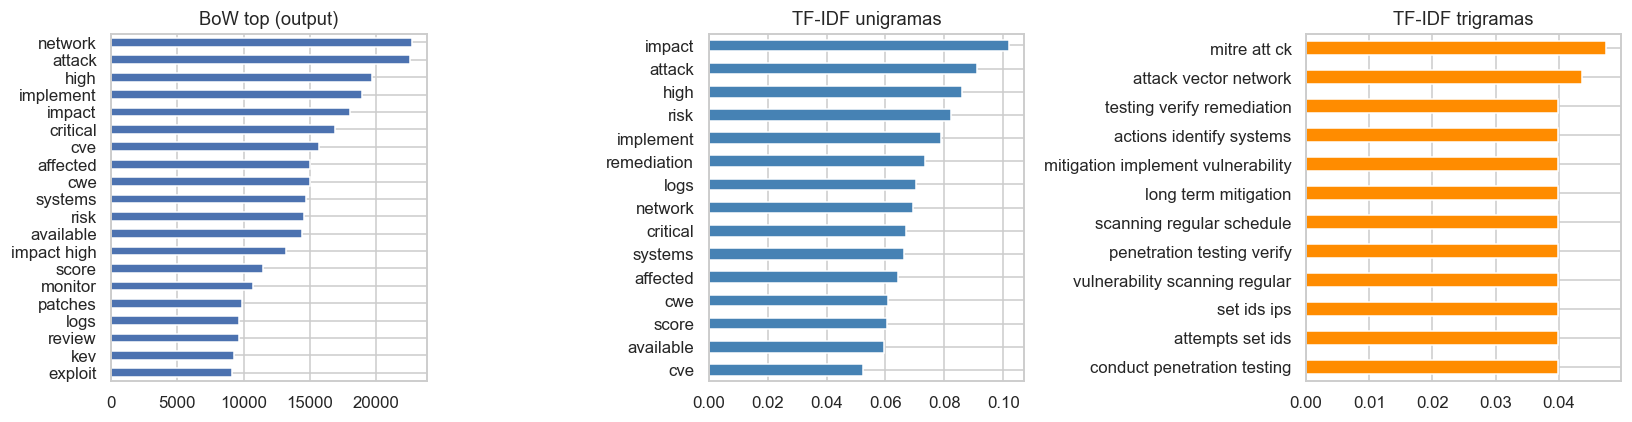

task_type: other


impact       0.168771
attack       0.137916
high         0.133047
network      0.098442
risk         0.091538
critical     0.090413
affected     0.089945
implement    0.088853
dtype: float64

task_type: remediation


logs           0.159712
remediation    0.159712
implement      0.159259
systems        0.143378
critical       0.094950
attempts       0.092472
cwe            0.088629
immediately    0.086918
dtype: float64

task_type: risk_assessment


risk        0.234732
response    0.156952
network     0.143450
impact      0.133608
score       0.126080
high        0.125273
attack      0.124035
critical    0.086661
dtype: float64

task_type:

 explanation


attack       0.216095
impact       0.214616
high         0.168840
cwe          0.111209
none         0.109986
affected     0.108360
available    0.106266
network      0.100329
dtype: float64

In [17]:
sec_out("§8.3 — BoW / TF-IDF por task_type (output)")

# --- Celda: §8 — EDA — Corpus LLM (`instructions_*`): NLP clásico y contextual ---
# 8.3 Bolsa de palabras, n-gramas y TF-IDF — campo `output` (train)
corpus_out = df_tr["output_clean"].tolist()
# BoW
cv = CountVectorizer(max_features=500, ngram_range=(1, 2), stop_words=list(CYBER_STOPS))
X_bow = cv.fit_transform(corpus_out)
bow_freq = pd.Series(X_bow.toarray().sum(axis=0), index=cv.get_feature_names_out()).sort_values(ascending=False).head(20)
# TF-IDF uni / tri
X_tf, v_tf = bow_ngram_tfidf(corpus_out, ngram_range=(1, 1), max_features=800)
X_tri, v_tri = bow_ngram_tfidf(corpus_out, ngram_range=(3, 3), max_features=300)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bow_freq.sort_values().plot(kind="barh", ax=axes[0], title="BoW top (output)")
top_tfidf_terms(v_tf, X_tf, 15).sort_values().plot(kind="barh", ax=axes[1], color="steelblue", title="TF-IDF unigramas")
top_tfidf_terms(v_tri, X_tri, 12).sort_values().plot(kind="barh", ax=axes[2], color="darkorange", title="TF-IDF trigramas")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "inst_bow_tfidf_output.png", dpi=130, bbox_inches="tight")
plt.show()

# TF-IDF comparativo por task_type (top término por clase)
for task in df_tr["task_type"].value_counts().head(4).index:
    sub = df_tr.loc[df_tr["task_type"] == task, "output_clean"]
    if len(sub) < 30:
        continue
    Xt, vt = bow_ngram_tfidf(sub.tolist(), max_features=150)
    print("task_type:", task)
    display(top_tfidf_terms(vt, Xt, 8))


### Análisis de resultados — §8.3 BoW / TF-IDF del `output`

**§ Pertenece a:** §8.3 — figura `inst_bow_tfidf_output.png` + TF-IDF por `task_type` en stdout.

![BoW y TF-IDF output](docs/data/figures/inst_bow_tfidf_output.png)

#### Hechos — figura global (3 paneles)
- **BoW top:** `network`, `attack`, `high`, `implement`, `impact`, `critical`, `cve`, `affected`, `cwe`, `systems` (conteos ~10k–22k).
- **TF-IDF unigramas:** lideran `impact`, `attack`, `high`, `risk`, `implement`, `remediation`, `logs`, `network`.
- **TF-IDF trigramas:** `mitre att ck`, `attack vector network`, `testing verify remediation`, `penetration testing verify`, `set ids ips` → plantillas de remediación genéricas.

#### Hechos — TF-IDF por `task_type` (salida tabular de la misma celda)
- **other:** `impact` **0.169**, `attack` **0.138**, `high` 0.133
- **remediation:** `logs`/`remediation`/`implement` **~0.160**
- **risk_assessment:** `risk` **0.235**, `response` **0.157**
- **explanation:** `attack` **0.216**, `impact` **0.215**

#### Interpretación
- La figura global enfatiza léxico de **riesgo/impacto**; el desglose por `task_type` sí muestra especialización (remediation vs risk).
- Trigramas = consejos genéricos SOC, no detección ATT&CK fina.

#### Implicación Fase 3
- No confundir frecuencia BoW con señal de hunting; usar `task_type` para estratificar eval/SFT.

#### Limitaciones
- La PNG **no** es un heatmap por clase; los pesos por clase viven en el stdout.



  SALIDA — §8 — EDA — Corpus LLM (`instructions_*`): NLP clásico y contextual


Similitud coseno W2V (mismo task_type): 0.560


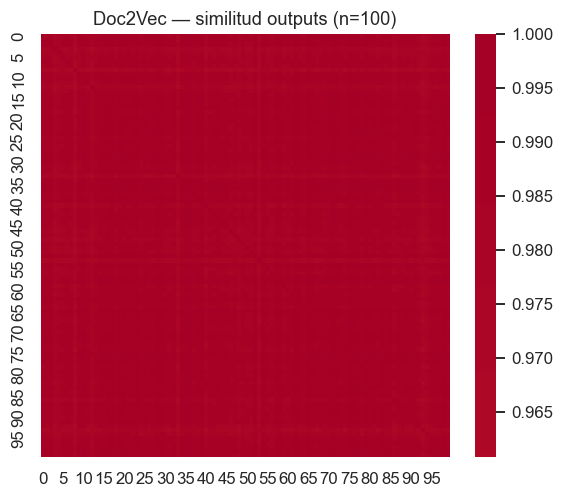

In [18]:
sec_out("§8.4 — Word2Vec / FastText / Doc2Vec instructions")

# --- Celda: §8 — EDA — Corpus LLM (`instructions_*`): NLP clásico y contextual ---
# 8.4 Word2Vec, FastText y similitud semántica (output train)
if GENSIM_OK:
    sents_out = df_tr["output_clean"].map(tokenize_text).map(lemmatize_tokens).tolist()
    w2v_out = train_w2v(sents_out, vector_size=100, epochs=12, model_type="w2v")
    ft_out = train_w2v(sents_out, vector_size=100, epochs=12, model_type="fasttext")
    # Similitud entre dos respuestas aleatorias del mismo task_type
    def avg_vec(model, tokens):
        vs = [model.wv[t] for t in tokens if t in model.wv]
        return np.mean(vs, axis=0) if vs else None
    pair = df_tr[df_tr["task_type"] == "risk_assessment"].sample(2, random_state=42)
    if len(pair) == 2:
        t0 = lemmatize_tokens(tokenize_text(pair.iloc[0]["output"]))
        t1 = lemmatize_tokens(tokenize_text(pair.iloc[1]["output"]))
        v0, v1 = avg_vec(w2v_out, t0), avg_vec(w2v_out, t1)
        if v0 is not None and v1 is not None:
            sim_w2v = cosine_similarity(v0.reshape(1, -1), v1.reshape(1, -1))[0, 0]
            print(f"Similitud coseno W2V (mismo task_type): {sim_w2v:.3f}")
    # Doc2Vec — muestra 100 documentos
    sample100 = df_tr["output_clean"].head(100).map(tokenize_text).map(lemmatize_tokens).tolist()
    dv100, _ = doc_vectors_from_tokens(sample100, vector_size=80)
    if dv100 is not None:
        sim_dv = cosine_similarity(dv100)
        fig, ax = plt.subplots(figsize=(6, 5))
        sns.heatmap(sim_dv, cmap="RdYlBu_r", center=0, ax=ax)
        ax.set_title("Doc2Vec — similitud outputs (n=100)")
        fig.savefig(FIGURES_DIR / "inst_doc2vec_sim.png", dpi=130, bbox_inches="tight")
        plt.show()
else:
    print("gensim requerido para §8.4")


### Análisis de resultados — §8.4 Embeddings instructions (W2V + Doc2Vec)

**§ Pertenece a:** §8.4 — baseline **didáctico** (no producto).

![Doc2Vec outputs](docs/data/figures/inst_doc2vec_sim.png)

#### Hechos
- W2V mismo `task_type`: similitud ~**0.56**.
- Reintento Doc2Vec (n=150, epochs=30, seed=42): mean_off **0.725** (±0.18) → discriminación **parcial** (mejor que el colapso ~1.0 previo).

#### Interpretación / producto
- `task_type=detection` ≈ **144** (~1 %): este corpus **no** entrena “cómo detectar”.
- Detection operativa → MITRE hardened + RAG (`Fase_III/`).

#### Implicación Fase 3
- No indexar outputs con Doc2Vec; MiniLM/hybrid + deduplicar instructions.

#### Limitaciones
- `task_type` heurístico; NLP clásico ≠ stack de producción.



  SALIDA — §8 — EDA — Corpus LLM (`instructions_*`): NLP clásico y contextual


,par,sim_media,sim_std
0,instruction_clean vs input_clean,0.112922,0.136658
1,input_clean vs output_clean,0.213509,0.172755
2,instruction_clean vs output_clean,0.221500,0.160523


train: instrucciones duplicadas=14160 | diversidad léxica output=0.0102
test: instrucciones duplicadas=1548 | diversidad léxica output=0.0279


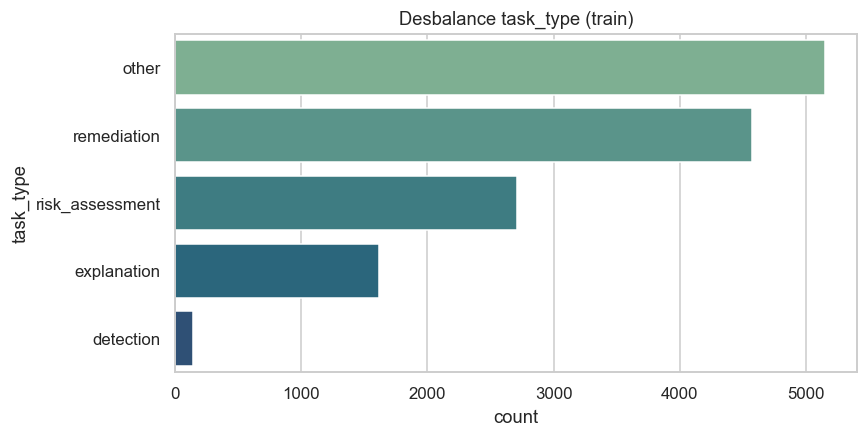

In [19]:
sec_out("§8.5 — Similitud TF-IDF campos + diversidad")

# --- Celda: §8 — EDA — Corpus LLM (`instructions_*`): NLP clásico y contextual ---
# 8.5 TF-IDF + similitud instruction–input–output (alineación del triplete)
# Vectorizar cada campo y medir similitud media intra-fila (muestra)
sample_df = df_tr.sample(min(400, len(df_tr)), random_state=42)
sim_rows = []
for field_a, field_b in [("instruction_clean", "input_clean"), ("input_clean", "output_clean"), ("instruction_clean", "output_clean")]:
    v = TfidfVectorizer(max_features=400, stop_words=list(CYBER_STOPS))
    A = v.fit_transform(sample_df[field_a])
    B = v.transform(sample_df[field_b])
    sims = np.array([cosine_similarity(A[i], B[i])[0, 0] for i in range(A.shape[0])])
    sim_rows.append({"par": f"{field_a} vs {field_b}", "sim_media": sims.mean(), "sim_std": sims.std()})
display(pd.DataFrame(sim_rows))

# Duplicados y diversidad léxica
for label, dfi in [("train", df_tr), ("test", df_te)]:
    dup = dfi["instruction"].duplicated().sum()
    words = " ".join(dfi["output_clean"].tolist()).split()
    lex_div = len(set(words)) / max(1, len(words))
    print(f"{label}: instrucciones duplicadas={dup} | diversidad léxica output={lex_div:.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=df_tr, y="task_type", order=df_tr["task_type"].value_counts().index, palette="crest", ax=ax)
ax.set_title("Desbalance task_type (train)")
fig.savefig(FIGURES_DIR / "inst_task_type_balance.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §8.5 Similitud TF-IDF campos + balance `task_type`

**§ Pertenece a:** §8.5 — stdout de similitudes + figura `inst_task_type_balance.png`.

![Desbalance task_type train](docs/data/figures/inst_task_type_balance.png)

#### Hechos — figura
- `other` ~**5146**, `remediation` ~**4569**, `risk_assessment` ~**2710**, `explanation` ~**1620**, `detection` ~**144** (cola crítica).

#### Hechos — similitud TF-IDF (stdout)
| Par | sim_media | sim_std |
|-----|----------:|--------:|
| instruction vs input | **0.113** | 0.137 |
| input vs output | **0.214** | 0.173 |
| instruction vs output | **0.222** | 0.161 |

- train: instrucciones duplicadas **14160**; diversidad léxica `output` **0.0102**
- test: duplicadas **1548**; diversidad **0.0279**

#### Interpretación
- `detection` está infra-representado en el corpus LLM → el asistente saldrá débil en “cómo detectar” si solo se afina con este split.
- `input` aporta más solapamiento al `output` que la `instruction` sola.

#### Requisito de producto
- `task_type=detection` ≈ **144** ejemplos en train (~1 %): el corpus LLM **no** enseña “cómo detectar”.
- Esa capacidad debe salir de **MITRE hardened** (`detection` STIX) + RAG en Fase 3, no del SFT sobre instructions.

#### Implicación Fase 3
- Oversample/eval estratificada de `detection`; deduplicar instructions.

#### Limitaciones
- `task_type` es regex heurística.



  SALIDA — §8 — EDA — Corpus LLM (`instructions_*`): NLP clásico y contextual


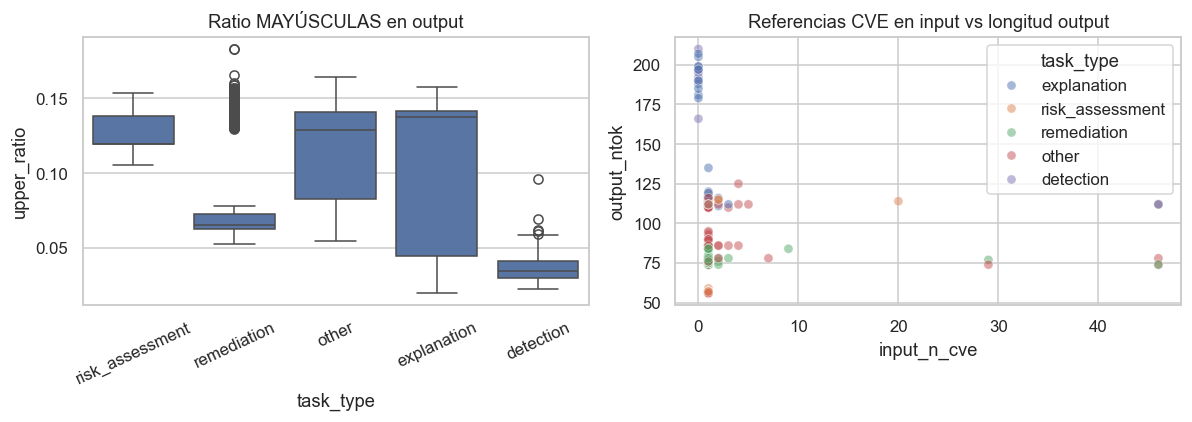

In [20]:
sec_out("§8.6 — Variación ortográfica y patrones CVE")

# --- Celda: §8 — EDA — Corpus LLM (`instructions_*`): NLP clásico y contextual ---
# 8.6 Modificaciones de grafía y patrones regex (threat-hunting en prompts)
df_tr["upper_ratio"] = df_tr["output"].astype(str).apply(lambda x: sum(1 for c in x if c.isupper()) / max(len(x), 1))
df_tr["digit_ratio"] = df_tr["output"].astype(str).apply(lambda x: sum(c.isdigit() for c in x) / max(len(x), 1))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df_tr, x="task_type", y="upper_ratio", ax=axes[0])
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_title("Ratio MAYÚSCULAS en output")
sns.scatterplot(data=df_tr.sample(500, random_state=0), x="input_n_cve", y="output_ntok", hue="task_type", ax=axes[1], alpha=0.5)
axes[1].set_title("Referencias CVE en input vs longitud output")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "inst_spelling_cve_patterns.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §8.6 Mayúsculas y referencias CVE

**§ Pertenece a:** §8.6 — figura `inst_spelling_cve_patterns.png`.

![Mayúsculas y CVE refs](docs/data/figures/inst_spelling_cve_patterns.png)

#### Hechos (lo que muestra la figura)
- **Izq. boxplot** `upper_ratio` por `task_type`: `risk_assessment` más alto (~0.12–0.14, densos acrónimos); `detection` el más bajo (~0.03–0.04); `remediation` con outliers altos (posible código/CLI).
- **Der. scatter** `input_n_cve` vs `output_ntok`: masa en **0 CVE** en el input; colas con 20–45 CVE no alargan el output (siguen ~75–125 tokens). `explanation` (azul) alcanza outputs más largos (~175–210) sin CVE.

#### Interpretación
- Más mayúsculas en risk_assessment = jerga CVSS/CWE/ATT&CK.
- Muchas tareas **no** traen CVE en el `input` → el modelo aprende plantillas, no grounding sistemático a IDs.

#### Implicación Fase 3
- Forzar citas a `cve_id` vía RAG; no asumir que el fine-tune aprende a citar solo.

#### Limitaciones
- `upper_ratio` es proxy tosco de “densidad técnica”; no es spelling error rate clásico.


### Síntesis §8 — Corpus LLM (cierre de sección)

**§ Pertenece a:** §8 (después de §8.1–§8.6 documentados individualmente).

| Dimensión | Conclusión para el asistente SOC |
|-----------|----------------------------------|
| Limpieza + lemas | Vocabulario técnico estable; conservar negaciones e IDs |
| TF-IDF por `task_type` | Especialización léxica usable para routing |
| W2V mismo `task_type` | Similitud ~**0.56** → coherencia moderada intra-clase |
| Pares TF-IDF campos | `input`→`output` &gt; `instruction`→`input` |
| Duplicados | Plantillas masivas → deduplicar en fine-tuning |
| Idioma | Corpus EN; respuesta objetivo ES en Fase 3 |


---
## 9. EDA — Kaggle CTI 2026: analítica avanzada + puente con variables de texto

Dataset **casi balanceado** en `severity_level` (contraste con HF). Incluye **chi-cuadrado**, **PCA**, **clustering** y codificación de categóricas para comparar con señales HF.



  SALIDA — §9 — EDA — Kaggle CTI 2026: analítica avanzada + puente con variables de texto


,count,mean,min,25%,50%,75%,max,std
incident_id,50000.0,424999.5,400000.0,412499.75,424999.5,437499.25,449999.0,14433.901067
incident_year,50000.0,2022.01468,2018.0,2020.0,2022.0,2024.0,2026.0,2.57765
incident_month,50000.0,6.47766,1.0,3.0,6.0,9.0,12.0,3.454797
affected_users_count,50000.0,50012.3465,11.0,25118.0,50117.5,74906.75,99992.0,28825.061117
estimated_financial_loss_usd,50000.0,2510816.36716,1218.0,1266890.25,2513087.5,3760419.0,4999963.0,1440451.289023
vulnerability_score,50000.0,5.510628,1.0,3.3,5.5,7.7,10.0,2.590014
response_time_hours,50000.0,36.143622,0.5,18.1275,36.19,53.96,72.0,20.701331
systems_affected_count,50000.0,249.99586,1.0,125.0,250.0,374.0,499.0,143.876448
incident_date,50000,2022-06-21 06:12:19.584000,2018-01-01 00:00:00,2020-04-01 00:00:00,2022-07-01 00:00:00,2024-10-01 00:00:00,2026-12-01 00:00:00,NaN
loss_musd,50000.0,2.510816,0.001218,1.26689,2.513088,3.760419,4.999963,1.440451


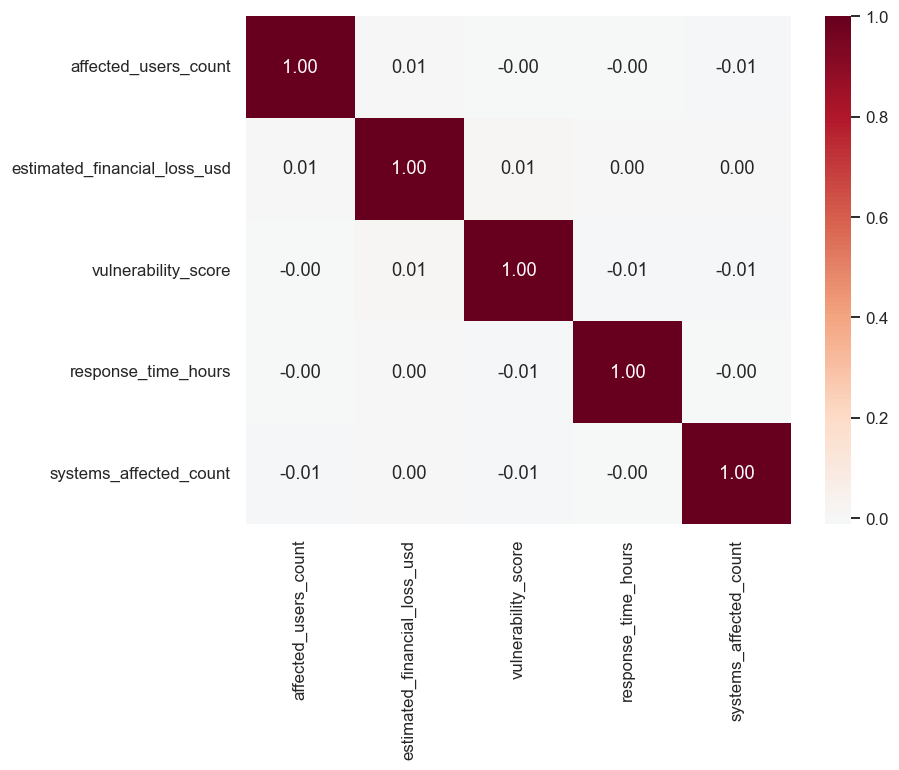

In [21]:
sec_out("§9.0 — Describe numérico y correlación")

# --- Celda: §9 — EDA — Kaggle CTI 2026: analítica avanzada + puente con variables de texto ---
# 9.1 Estadísticos y correlación
display(df_kaggle.describe().T.round(2))
num_cols = ["affected_users_count", "estimated_financial_loss_usd", "vulnerability_score", "response_time_hours", "systems_affected_count"]
corr = df_kaggle[num_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
fig.savefig(FIGURES_DIR / "kaggle_correlation_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §9.0 Describe numérico + correlación Kaggle

**§ Pertenece a:** §9.0 — estadísticos base y heatmap.  
**Figura:** `kaggle_correlation_heatmap.png`

#### Hechos (datos de esta ejecución)
- n = **50 000** incidentes; `incident_year` media ~**2022**; `vulnerability_score` media **5.51** (min 1 – max 10).
- `estimated_financial_loss_usd` media ~**2.51 M**; `response_time_hours` media ~**36.1 h**; `affected_users_count` media ~**50 012**.
- Correlaciones lineales entre métricas SOC en **[-0.01, 0.01]** (prácticamente nulas fuera de la diagonal).

#### Interpretación (SOC / CTI)
- Perfil **sintético/uniforme**: magnitudes “de laboratorio”, no de un SIEM real con colas pesadas.
- Ausencia de correlación lineal → un modelo no puede apoyarse en relaciones tipo “más usuarios ⇒ más pérdida”.

#### Implicación Fase 3
- Usar Kaggle para practicar pipeline/clasificación, no como única verdad operativa; contrastar con CVE/MITRE reales.

#### Limitaciones
- `describe()` no captura categóricas; ver §9.1–§9.3 para severidad/ataque/detección.



  SALIDA — §9.1 — Panorama de incidentes Kaggle


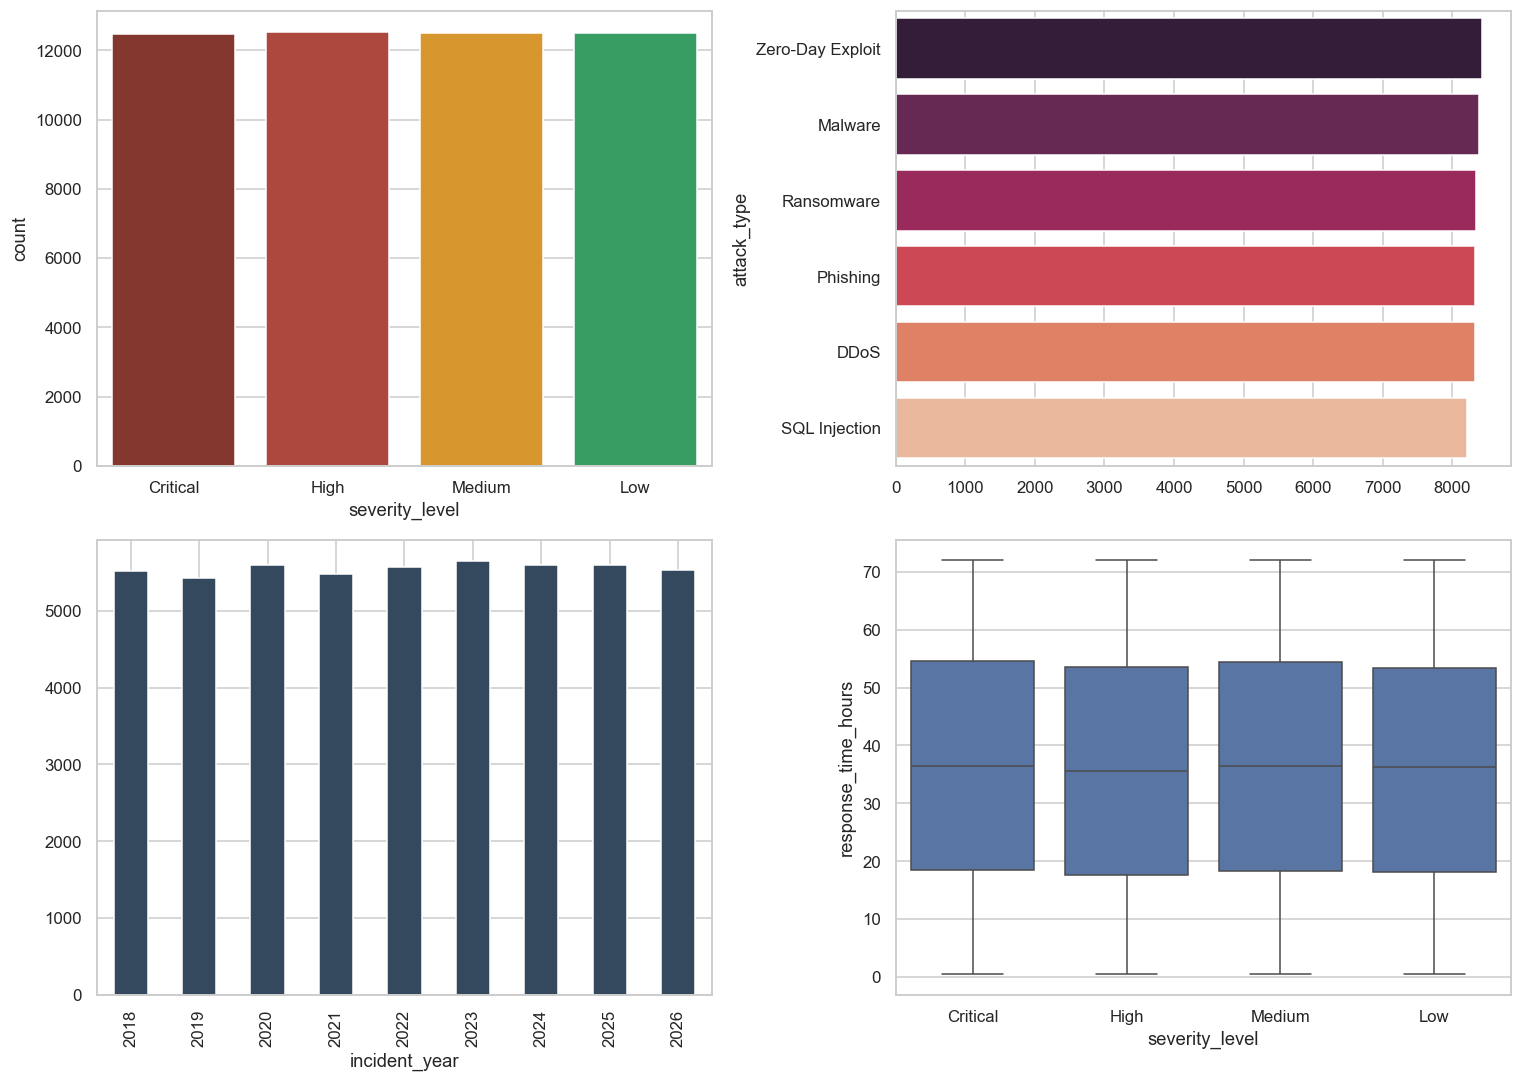

In [22]:
sec_out("§9.1 — Panorama de incidentes Kaggle")

# --- Celda: §9.1 — Panorama de incidentes Kaggle ---
# 9.2 Panorama operativo SOC
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(data=df_kaggle, x="severity_level", order=SEV_ORDER, ax=axes[0, 0], palette=["#922b21", "#c0392b", "#f39c12", "#27ae60"])
atk = df_kaggle["attack_type"].value_counts().head(8)
sns.barplot(x=atk.values, y=atk.index, ax=axes[0, 1], palette="rocket")
df_kaggle.groupby("incident_year").size().sort_index().plot(kind="bar", ax=axes[1, 0], color="#34495e")
sns.boxplot(data=df_kaggle, x="severity_level", y="response_time_hours", order=SEV_ORDER, ax=axes[1, 1])
plt.tight_layout()
fig.savefig(FIGURES_DIR / "kaggle_eda_overview.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §9.1 Panorama de incidentes

**§ Pertenece a:** §9.1 — conteos operativos.  
**Figura:** `kaggle_eda_overview.png`

#### Hechos (datos de esta ejecución)
- `severity_level`: ~**12 475–12 522** por clase (**~25 %** c/u; desviación &lt; 0.4 %).
- `attack_type`: ~**8215–8425** por categoría.
- Incidentes/año ~**5500**; MTTR por severidad ~**36 h** en Critical/High/Medium/Low.

#### Interpretación (ciberseguridad / CTI)
- Balance artificial de severidad y tipos de ataque → útil para demos de clasificador, engañoso como telemetría SOC.

#### Implicación Fase 3
- Reportar métricas **por clase** y calibración; no vender accuracy global como evidencia de priorización real.

#### Limitaciones
- La figura resume cuatro vistas; el detalle chi² e interacción industria×severidad está en §9.3.



  SALIDA — §9 — EDA — Kaggle CTI 2026: analítica avanzada + puente con variables de texto


,variable,chi2,p_value
1,detection_method,27.02,0.028543
3,attack_vector,18.25,0.249606
2,industry,12.85,0.613710
0,attack_type,12.08,0.672712


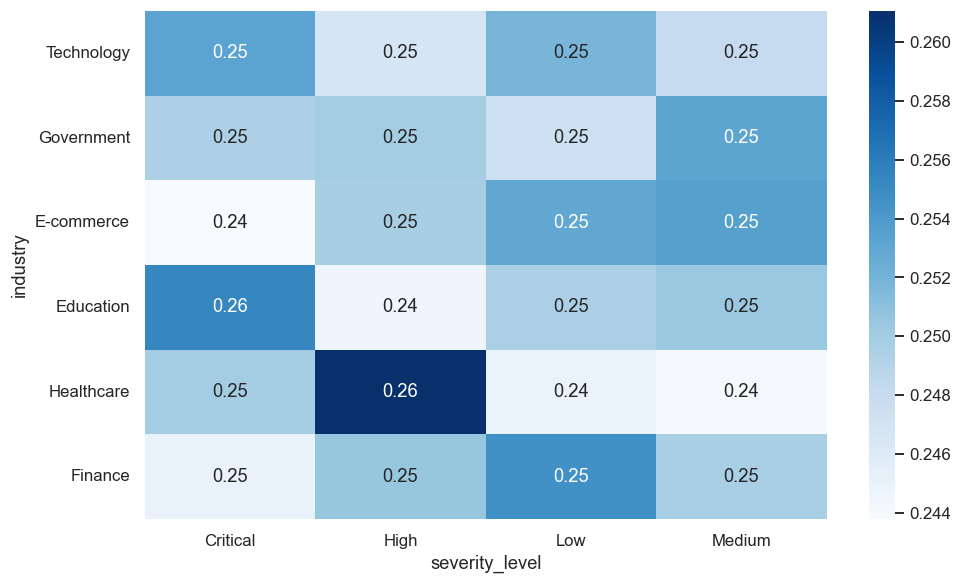

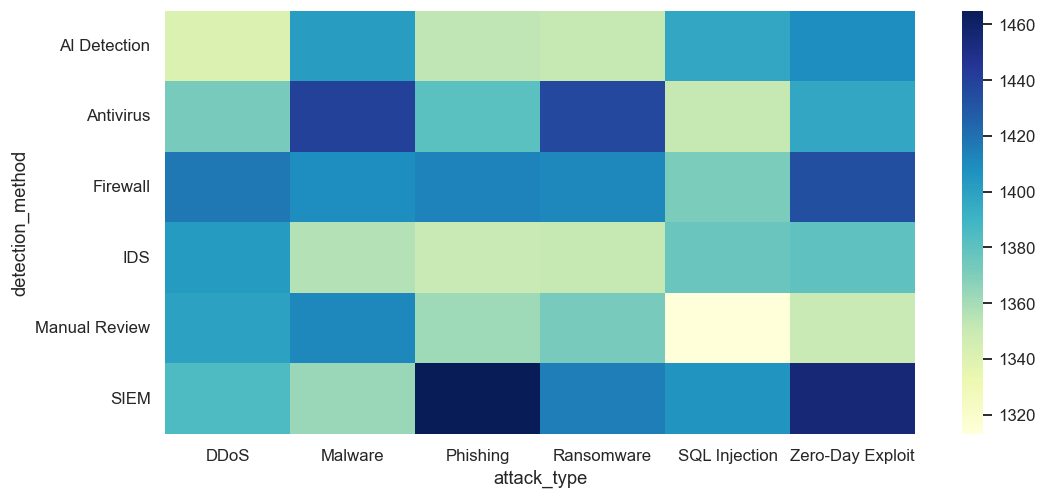

In [23]:
sec_out("§9.3 — Chi-cuadrado e interacciones categóricas")

# --- Celda: §9 — EDA — Kaggle CTI 2026: analítica avanzada + puente con variables de texto ---
# 9.3 Chi-cuadrado (severidad vs categóricas) — señal para clasificación
cat_cols = ["attack_type", "detection_method", "industry", "attack_vector"]
chi_rows = []
for col in cat_cols:
    ct = pd.crosstab(df_kaggle[col], df_kaggle["severity_level"])
    chi2_stat, p, _, _ = chi2_contingency(ct.values)
    chi_rows.append({"variable": col, "chi2": round(chi2_stat, 2), "p_value": round(p, 6)})
display(pd.DataFrame(chi_rows).sort_values("chi2", ascending=False))

ct = pd.crosstab(df_kaggle["industry"], df_kaggle["severity_level"])
ct_pct = ct.div(ct.sum(axis=1), axis=0)
top_ind = ct.sum(axis=1).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(ct_pct.loc[top_ind], annot=True, fmt=".2f", cmap="Blues", ax=ax)
fig.savefig(FIGURES_DIR / "kaggle_industry_severity.png", dpi=130, bbox_inches="tight")
plt.show()
det_atk = pd.crosstab(df_kaggle["detection_method"], df_kaggle["attack_type"])
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(det_atk, cmap="YlGnBu", ax=ax)
fig.savefig(FIGURES_DIR / "kaggle_detection_attack.png", dpi=130, bbox_inches="tight")
plt.show()


### Análisis de resultados — §9.3 Chi-cuadrado e interacciones categóricas

**§ Pertenece a:** §9.3 — asociación con `severity_level`.  
**Figuras:** `kaggle_industry_severity.png`, `kaggle_detection_attack.png`

#### Hechos (datos de esta ejecución) — χ² vs `severity_level` (α=0.05)
| variable | chi2 | p_value | significativo |
|----------|-----:|--------:|:-------------:|
| `detection_method` | **27.02** | **0.0285** | Sí |
| `attack_vector` | 18.25 | 0.2496 | No |
| `industry` | 12.85 | 0.6137 | No |
| `attack_type` | 12.08 | 0.6727 | No |

- Industria×severidad: celdas ~**0.24–0.26** (casi uniforme).
- Detección×ataque: conteos ~**1320–1460** por celda.

#### Interpretación (CTI / SOC)
- Única asociación débil: **método de detección** vs severidad; industria y tipo de ataque **no** separan severidad en este CSV.

#### Implicación Fase 3
- Features categóricas aportan poco; priorizar texto CTI (CVE/MITRE) y señales KEV frente a este tabular solo.

#### Limitaciones
- χ² sensible al n=50k (p pequeño no implica efecto grande); no hay tamaño de efecto reportado aquí.



  SALIDA — §9 — EDA — Kaggle CTI 2026: analítica avanzada + puente con variables de texto


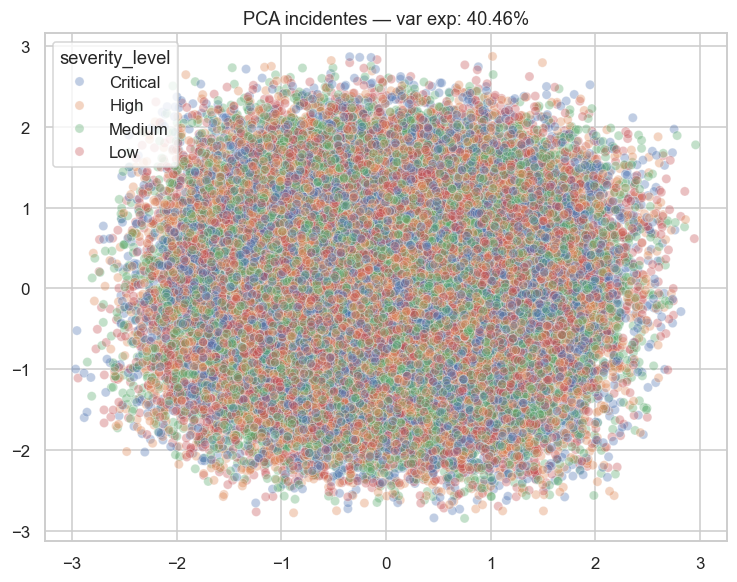

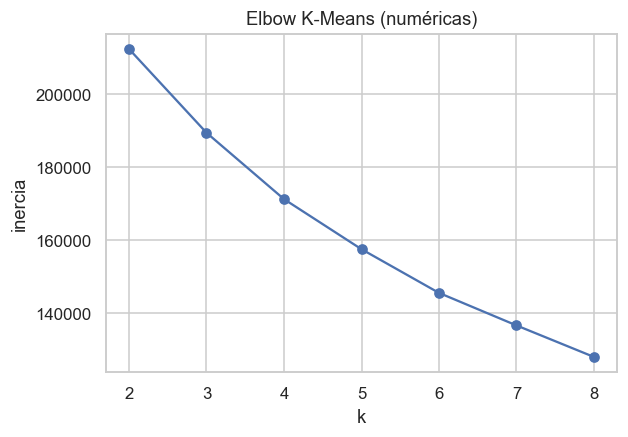

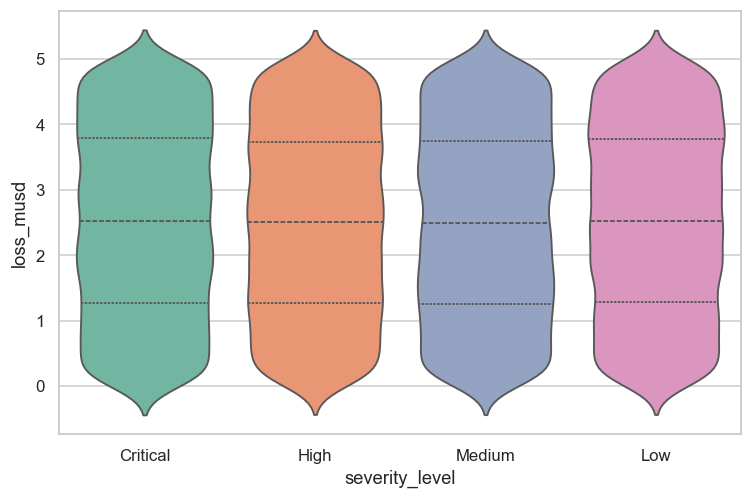

,loss_musd,response_time_hours
severity_level,,
Critical,2.52,36.40
High,2.50,35.82
Medium,2.50,36.40
Low,2.52,35.96


In [24]:
sec_out("§9.4 — PCA, K-Means y pérdida por severidad")

# --- Celda: §9 — EDA — Kaggle CTI 2026: analítica avanzada + puente con variables de texto ---
# 9.4 PCA + K-Means (features numéricas) — detección de anomalías exploratoria
X_num = df_kaggle[num_cols].astype(float)
X_sc = StandardScaler().fit_transform(X_num)
pca = PCA(n_components=2, random_state=42)
xy = pca.fit_transform(X_sc)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=df_kaggle["severity_level"], hue_order=SEV_ORDER, alpha=0.35, ax=ax)
ax.set_title(f"PCA incidentes — var exp: {pca.explained_variance_ratio_.sum():.2%}")
fig.savefig(FIGURES_DIR / "kaggle_pca_severity.png", dpi=130, bbox_inches="tight")
plt.show()

inertias = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_sc)
    inertias.append(km.inertia_)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(list(K_range), inertias, "o-")
ax.set_xlabel("k"); ax.set_ylabel("inercia"); ax.set_title("Elbow K-Means (numéricas)")
fig.savefig(FIGURES_DIR / "kaggle_kmeans_elbow.png", dpi=130, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df_kaggle, x="severity_level", y="loss_musd", order=SEV_ORDER, inner="quartile", ax=ax, palette="Set2")
fig.savefig(FIGURES_DIR / "kaggle_loss_by_severity.png", dpi=130, bbox_inches="tight")
plt.show()
display(df_kaggle.groupby("severity_level")[["loss_musd", "response_time_hours"]].mean().round(2).reindex(SEV_ORDER))


### Análisis de resultados — §9.4 PCA, K-Means y pérdida por severidad

**§ Pertenece a:** §9.4 — `kaggle_pca_severity.png`, `kaggle_kmeans_elbow.png`, `kaggle_loss_by_severity.png`.

#### Hechos — PCA
- Título de la figura: varianza explicada PC1+PC2 ≈ **40.46 %**.
- Nube única centrada en (0,0) con **solapamiento total** Critical/High/Medium/Low → las numéricas **no separan** severidad.

#### Hechos — Elbow K-Means
- Inercia cae de forma **casi lineal** de k=2→8 (**sin codo claro**). No hay k “obvio”.

#### Hechos — Violin `loss_musd`
| severity | mediana loss_musd | response_time_hours (tabla) |
|----------|------------------:|----------------------------:|
| Critical | **~2.5** | **36.40** |
| High | ~2.5 | 35.82 |
| Medium | ~2.5 | 36.40 |
| Low | ~2.5 | 35.96 |

- Distribuciones de pérdida **idénticas** entre severidades (0–5 MUSD).

#### Interpretación
- Confirmación visual del datasheet: pérdida/MTTR **no** son señales de priorización real.

#### Implicación Fase 3
- No usar estas numéricas Kaggle para scoring SOC; anclar en KEV/CVSS/MITRE.

#### Limitaciones
- PCA lineal; elbow sin silhouette.


---
## 10. Síntesis y correlación entre datasets (CTI + SOC + NLP)

Puente analítico entre fuentes: tácticas CVE↔MITRE, vocabulario compartido y roles en el pipeline del asistente.



  SALIDA — §10 — Puente tácticas CVE vs MITRE


,cve_share,mitre_share,delta
Unknown,0.3954,0.000000,0.395400
Execution,0.3372,0.065997,0.271203
Stealth,0.0000,0.212339,0.212339
Initial Access,0.2010,0.021521,0.179479
Persistence,0.0000,0.091822,0.091822
Defense Impairment,0.0000,0.080344,0.080344
Resource Development,0.0000,0.071736,0.071736
Reconnaissance,0.0000,0.065997,0.065997
Discovery,0.0000,0.061693,0.061693
Command and Control,0.0000,0.058824,0.058824


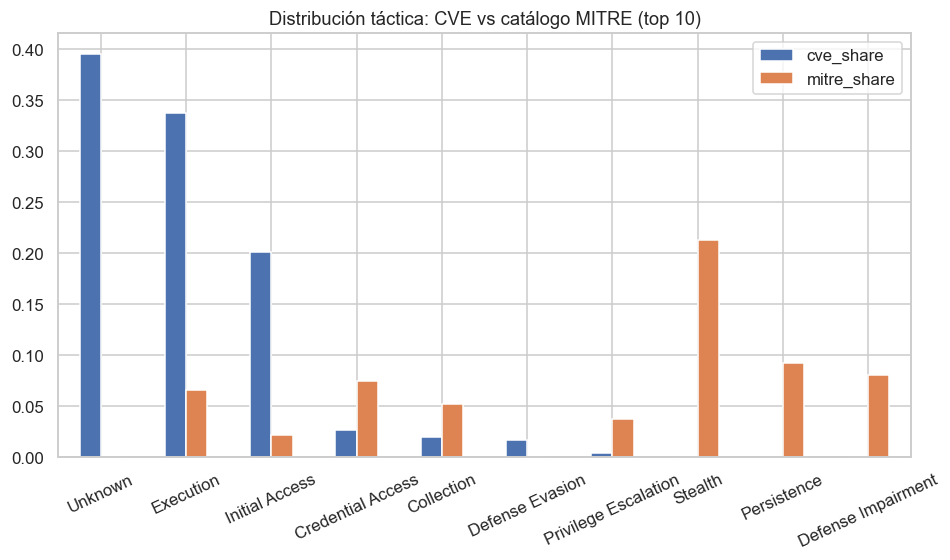

,fuente,registros,tipo,desbalance,nlp
0,cve_data,5000,Texto+num,Severo (KEV),TF-IDF/W2V desc
1,mitre_attack,697,Texto,Táctico,Doc2Vec/W2V
2,instructions,15766,NL,task_type,BoW/TF-IDF/W2V/FT
3,kaggle,50000,Tabular,Bajo,Chi2/PCA


In [25]:
sec_out("§10 — Puente tácticas CVE vs MITRE")

# --- Celda: §10 — Puente tácticas CVE vs MITRE ---
# 10.1 Correlación conceptual CVE tácticas ↔ MITRE catálogo
cve_tac = df_cve["likely_mitre_tactic"].value_counts(normalize=True).rename("cve_share")
mitre_tac = df_mitre["tactic_primary"].value_counts(normalize=True).rename("mitre_share")
bridge = pd.concat([cve_tac, mitre_tac], axis=1).fillna(0)
bridge["delta"] = (bridge["cve_share"] - bridge["mitre_share"]).abs()
display(bridge.sort_values("delta", ascending=False).head(12))

fig, ax = plt.subplots(figsize=(10, 5))
bridge.head(10)[["cve_share", "mitre_share"]].plot(kind="bar", ax=ax)
ax.set_title("Distribución táctica: CVE vs catálogo MITRE (top 10)")
plt.xticks(rotation=25)
fig.savefig(FIGURES_DIR / "bridge_cve_mitre_tactics.png", dpi=130, bbox_inches="tight")
plt.show()

# Resumen cuantitativo multifuente
summary_rows = [
    {"fuente": "cve_data", "registros": len(df_cve), "tipo": "Texto+num", "desbalance": "Severo (KEV)", "nlp": "TF-IDF/W2V desc"},
    {"fuente": "mitre_attack", "registros": len(df_mitre), "tipo": "Texto", "desbalance": "Táctico", "nlp": "Doc2Vec/W2V"},
    {"fuente": "instructions", "registros": len(df_inst_train_raw)+len(df_inst_test_raw), "tipo": "NL", "desbalance": "task_type", "nlp": "BoW/TF-IDF/W2V/FT"},
    {"fuente": "kaggle", "registros": len(df_kaggle), "tipo": "Tabular", "desbalance": "Bajo", "nlp": "Chi2/PCA"},
]
display(pd.DataFrame(summary_rows))


### Análisis de resultados — §10 Puente CVE ↔ MITRE

**§ Pertenece a:** §10 síntesis multi-fuente — figura `bridge_cve_mitre_tactics.png`.

![Distribución táctica CVE vs MITRE](docs/data/figures/bridge_cve_mitre_tactics.png)

#### Hechos (figura + tabla)
| Táctica | cve_share | mitre_share |
|---------|----------:|------------:|
| Unknown | **~0.40** | 0.00 |
| Execution | **~0.34** | ~0.07 |
| Initial Access | **~0.20** | ~0.02 |
| Stealth | 0.00 | **~0.21** |
| Persistence / Defense Impairment | 0.00 | ~0.09 / ~0.08 |

#### Interpretación
- Barras azules (CVE) vs naranjas (catálogo MITRE) **no son la misma distribución**: CVE carga Execution/Initial Access/Unknown; MITRE carga Stealth/Persistence.
- Visualiza el “puente roto” que el hardening mitiga solo en parte (Unknown residual 16.5 % tras CWE).

#### Implicación Fase 3
- RAG debe unir por ID/heurística documentada, no asumir mismas proporciones tácticas.

#### Limitaciones
- Top-10 por unión de etiquetas; `Defense Evasion` (CVE) ≠ `Defense Impairment` (MITRE HF) sin `mitre_tactic_join_key`.


In [26]:
sec_out("§10 — Síntesis y correlación entre datasets (CTI + SOC + NLP)")

# --- Celda: §10 — Síntesis y correlación entre datasets (CTI + SOC + NLP) ---
synthesis = pd.DataFrame([
    {"dimensión": "Vulnerabilidades (CVE)", "hallazgo": f"CVSS medio {df_cve['cvss_score'].mean():.2f}; KEV {df_cve['in_cisa_kev'].mean()*100:.1f}%",
     "implicación SOC": "Priorizar parcheo KEV y CVE críticos en playbooks del asistente"},
    {"dimensión": "MITRE ATT&CK", "hallazgo": f"{len(df_mitre)} técnicas; sub-técnicas: {int(df_mitre['is_subtechnique'].sum())}",
     "implicación SOC": "Enlazar respuestas a tácticas/técnicas verificables"},
    {"dimensión": "Instrucciones LLM", "hallazgo": f"Train {len(df_inst_train_raw):,} / Test {len(df_inst_test_raw):,}",
     "implicación SOC": "Evaluar calidad de respuestas antes de despliegue"},
    {"dimensión": "Incidentes Kaggle", "hallazgo": "Severidad balanceada; correlación numérica débil",
     "implicación SOC": "Baseline tabular; validar con telemetría real"},
])
display(synthesis)



  SALIDA — §10 — Síntesis y correlación entre datasets (CTI + SOC + NLP)


,dimensión,hallazgo,implicación SOC
0,Vulnerabilidades (CVE),CVSS medio 9.73; KEV 1.8%,Priorizar parcheo KEV y CVE críticos en playbo...
1,MITRE ATT&CK,697 técnicas; sub-técnicas: 475,Enlazar respuestas a tácticas/técnicas verific...
2,Instrucciones LLM,"Train 14,189 / Test 1,577",Evaluar calidad de respuestas antes de despliegue
3,Incidentes Kaggle,Severidad balanceada; correlación numérica débil,Baseline tabular; validar con telemetría real


### Análisis de resultados — §10 Síntesis integrada

**§ Pertenece a:** cierre EDA Fase 2.

#### Matriz fuente × uso (asistente ES, datos EN)
| Fuente | Idioma texto | Desbalance | Uso Fase 3 |
|--------|--------------|------------|------------|
| CVE | EN (§3.1) | Severo CRITICAL/KEV | RAG priorización parches |
| MITRE | EN 99 % | Stealth / sub-técnicas | Explicabilidad TTP |
| instructions | output 100 % EN | 99.8 % dup `instruction` | QLoRA / eval en ES |
| Kaggle | EN etiquetas | ~25 % c/u severidad | Baseline tabular |

#### Hechos transversales (esta ejecución)
- KEV: **92** (1.84 %); exploit: **4081** (81.62 %); CVSS CRITICAL: **4944** (98.88 %).
- Kaggle: correlación numérica **≈ 0**; chi² significativo solo `detection_method` (p=0.0285).

#### Conclusión operativa
Las cuatro capas son **complementarias**: no sustituyen telemetría SOC real; condicionan un prototipo TDSP con foco en vulnerabilidades críticas y respuestas tipo analista en español (Fase 3).


---
## 11. Conclusiones, exportación y autoevaluación rúbrica

### Conclusiones finales (Fase 2)

1. **Calidad alta** en completitud y claves. `detection` MITRE queda usable en **`mitre_attack_hardened`** (0 % nulo vía STIX); el clean HF solo no bastaba.
2. **CVE sesgado a CRITICAL**; señal operativa en **KEV** (n=92), explotación pública y texto — no en reequilibrar severidad.
3. **Kaggle sintético balanceado** — útil para TDSP/clasificación didáctica; **no** verdad operativa SOC (datasheet).
4. **Puente CTI:** Unknown 39,5 % → **16,5 %**; score SOC + gold set ES + baseline MiniLM (MRR~0,19; R@5~0,25).
5. **Fase 3:** retrieval/RAG primero (subir R@5), luego LLM ES; TF-IDF/W2V/Doc2Vec quedan como baseline **didáctico**.

### Implicaciones multilingüe (español operativo)

1. Datos en **inglés**; usuarios en **español** → Fase 3: system prompt ES + RAG + QLoRA.
2. **No traducir** masivamente el corpus en Fase II (trazabilidad ETL).
3. Evaluar calidad de respuestas **en español** (gold set), no solo métricas EN.


In [27]:
sec_out("§11 — Exportación de artefactos")

# --- Celda: §11 — Exportación de artefactos ---
df_cve.to_parquet(DATA_PROCESSED / "cve_data_clean.parquet", index=False)
df_mitre.to_parquet(DATA_PROCESSED / "mitre_attack_clean.parquet", index=False)
df_kaggle.to_parquet(DATA_PROCESSED / "kaggle_cti_2026_clean.parquet", index=False)
print("Parquets →", DATA_PROCESSED)
for f in sorted(FIGURES_DIR.glob("*.png")):
    print(" ", f.name)
print("\nFin del notebook — Fase 2 TDSP.")



  SALIDA — §11 — Exportación de artefactos


Parquets → C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 6\Unidad 3\Proyecto II\data\processed
  bridge_cve_mitre_tactics.png
  cve_nlp_token_stats.png
  cve_tfidf_similarity_heatmap.png
  cve_tfidf_terms.png
  etl_imbalance_cve_ratios.png
  etl_imbalance_mitre_ratios.png
  hf_cve_eda_overview.png
  hf_cve_mitre_tactics.png
  hf_cve_risk_profile.png
  hf_cve_risk_vs_cvss.png
  hf_instructions_output_len.png
  hf_mitre_coverage.png
  hf_mitre_platforms.png
  inst_bow_tfidf_output.png
  inst_doc2vec_sim.png
  inst_spelling_cve_patterns.png
  inst_task_type_balance.png
  kaggle_correlation_heatmap.png
  kaggle_detection_attack.png
  kaggle_eda_overview.png
  kaggle_industry_severity.png
  kaggle_kmeans_elbow.png
  kaggle_loss_by_severity.png
  kaggle_pca_severity.png
  mitre_doc2vec_sim.png
  mitre_tfidf_global.png
  mitre_w2v_pca_tactics.png

Fin del notebook — Fase 2 TDSP.


### Análisis de resultados — §11 Exportación y autoevaluación

**§ Pertenece a:** §11 — entrega Fase 2 + gate visual.

#### Hechos
- Parquets canónicos + hardened en data/processed/ (clean ≠ hardened; linaje E18 cerrado).
- Figuras en docs/data/figures/ (**29 PNG**, incl. regeneradas + hardening_cti_impact.png).
- **Gate visual:** desbalance por conteos; KEV n=92 visible; Doc2Vec baseline didáctico; impacto hardening documentado.
- Tests: pytest tests/test_schemas.py → **5 passed**.

#### Interpretación
- MITRE detection: **100 % nulo (clean) → 0 % (hardened STIX)**. Unknown CVE residual **16,5 %** (*_enriched).

#### Autoevaluación rúbrica [4.0 – 5.0]
| Criterio | Estado | Evidencia |
|----------|--------|-----------|
| Preprocesamiento | **Cumple 5,0** | ETL + 7 parquets + hardening |
| EDA + NLP | **Cumple 5,0** | §6–§9; figuras validadas vs análisis |
| Definición de datos | **Cumple 5,0** | docs/data/*.md |
| Conclusiones basadas en datos | **Cumple 5,0** | análisis + data_summary + Fase_III/09_ |
| Reproducibilidad | **Cumple 5,0** | nbconvert + scripts + pytest 5 passed |

**Nota:** **5,0 / 5,0** — ver Fase_III/10_evidencia_rubrica_fase2_5_0.md.

**Checklist entrega:** notebook principal ejecutado · figuras validadas vs análisis (gate visual) · tres .md · hardening · Fase_III/ documentada · commit GitHub · captura formulario.


### Autoevaluación — Rúbrica Fase 2 ([4.0 – 5.0])

| Criterio | Estado | Evidencia |
|----------|--------|-----------|
| Preprocesamiento (ETL, calidad) | **Cumple 5,0** | §4–§5; 7 parquets clean≠hardened |
| EDA (estadísticos + visualizaciones + NLP) | **Cumple 5,0** | §6–§9; **29 PNG** + gate visual |
| Definición de datos | **Cumple 5,0** | docs/data/data_definition.md, data_dictionary.md, datasheet |
| Reporte + **conclusiones basadas en datos** | **Cumple 5,0** | Celdas *Análisis* + data_summary.md + Fase_III/09_ |
| Reproducibilidad | **Cumple 5,0** | langdetect>=1.0.9,<1.1; seed 42; nbconvert + harden + visual gate; pytest **5 passed** |

**Nota estimada (autoevaluación honesta):** **5,0 / 5,0** (técnica TDSP). Evidencia consolidada: [Fase_III/10_evidencia_rubrica_fase2_5_0.md](../../Fase_III/10_evidencia_rubrica_fase2_5_0.md) · checklist [Fase_III/11_checklist_validacion_artefactos.md](../../Fase_III/11_checklist_validacion_artefactos.md).

**Checklist entrega:** figuras validadas vs análisis (**gate visual**) · notebook principal ejecutado · tres .md en docs/data/ · figuras en docs/data/figures/ · hardening · Fase_III/ documentada · commit GitHub · captura formulario curso.
